# E106 · When should a studio spend before a film's release? Timing P&A for box office returns

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify (after E104; E105 asks a related question for ticketed events) |
| **Data** | Real: **Wikidata** (CC0) for 302 films released in the US from November 2015 to December 2019, with release dates, box office, series membership and genres, and **Wikimedia pageviews** (CC0) for each film's English Wikipedia article and all its redirects, every day from 16 weeks before to 8 weeks after release. After an alignment check 206 films remain. The real data carry the **release calendar**, the **competition** from rival films in the same weeks, each film's **attention build-up and decay**, and its heavy-tailed **box office**. Simulated on top: P&A spend, 10 markets, weekly awareness tracking, exhibitors' screen allocation, weekly gross and studio returns, with **known** effects (true carryover $\lambda = 0.75$ a week), so every estimate and every recommended schedule can be graded against the truth |
| **You will learn** | The objective, **studio returns** (rental share of gross minus P&A), not gross · a **goodwill stock** with decay (Nerlove & Arrow 1962) feeding awareness · **screens as a mediator** decided from tracking 2-4 weeks out, and why controlling for them erases the effect of mid-campaign money · why a **cross-film model aligned on weeks to release** reads budget selection as media effect · why **one opening number per film** cannot identify a within-film timing effect, and what can: weekly tracking by market and a **randomised timing test** · a joint PyMC model of tracking, screens, opening and legs, with prior and posterior predictive checks · an experiment that buys **robustness to the model** · the **optimal schedule** by forward simulation over posterior draws, by film type, against the studios' own schedules and the naive model's advice |

In [1]:
import os

for v_ in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v_] = "1"  # nutpie runs chains as threads: a BLAS pool per chain would fight over the cores

import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from scipy.optimize import minimize
from scipy.special import expit, logit, softmax
from scipy.stats import binom

from pymc_challenges import data

RANDOM_SEED = 106
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
sys.modules.pop("jax", None)  # arviz leaves a lazy jax stub that makes matplotlib import all of JAX
pd.set_option("display.width", 160)
T_START = time.time()

BLUE, ORANGE, AQUA, PURPLE, RED = "#2a78d6", "#eb6834", "#1baf7a", "#8c5ac8", "#c8384e"
INK, MUTED, LIGHT = "#222222", "#8a8984", "#d9d8d3"
print(f"PyMC {pm.__version__}, ArviZ {az.__version__}")

PyMC 6.3.2, ArviZ 1.3.0


## The setting

A studio has a film opening on a Friday in twelve weeks and a prints-and-advertising (P&A) budget
to spend on it: trailers, television spots, posters, online video. By the time the release date is
fixed, the budget is mostly settled; the open question is **when** to spend it. Money spent ten
weeks out builds awareness that people will partly have forgotten by the opening. Money spent in
the last days reaches people while they decide, but too late for the exhibitors, who book screens
from the studio's tracking surveys a few weeks before release. Money spent after the opening
reaches a film whose fate is mostly sealed by its first weekend. The marketing lead's question is
the title of this notebook: when should the money go, to make the most of the box office?

Box office research has the pieces. Sawhney & Eliashberg (1996) model a film's audience in two
steps, a time to decide to see it and a time to act on it, and read the rate of deciding as where
promotion and word of mouth do their work.
Elberse & Eliashberg (2003) show that the number of screens a film opens on is itself an outcome,
set by exhibitors from what they expect the film to do, and that it carries much of what marketing
does for the opening. Liu (2006) shows that word of mouth around the release - its volume more
than its tone - predicts how a film's grosses hold up afterwards. Ainslie, Dreze & Zufryden (2005)
model how releases compete for the same audience in the same weeks. Einav (2007) warns that
seasonality in box office mixes demand with the studios' own choice to put strong films in the
best weekends. And De Vany & Walls (1999) document how heavy-tailed box office is: a few films
take most of it.

All of that makes timing hard to measure. Every film follows the same ramp into its release, so on
a "weeks to release" clock spend and attention rise together whatever media does. Budgets are set
from expected gross, so big films get big budgets and longer campaigns: E104's "budget follows
size" trap at full strength. Spend reacts to tracking: a film that tracks badly gets a late push.
And each film has one opening weekend, one number, against sixteen weeks of spend.

No public data hold studios' spend by week, so we do what E102-E104 did: take a real baseline and
plant known effects on it. The real part is the release calendar of 206 films, how much attention
each drew around its release (from Wikipedia pageviews, which already carry the real campaigns),
who it competed with, and how big it was. On top we simulate spend, awareness surveys, screens and
grosses in ten markets, with a known carryover of media, a known exhibitors' rule and known decay
of the gross. The studio's objective is its **returns**: its share of the gross (the rental),
minus what it spent; home video and streaming are left out. Since the rental share falls week by
week, returns and gross can call for different schedules, and part F checks whether they do.

| part | question | tool |
|---|---|---|
| A | What do real release calendars and attention curves look like? | Wikidata, pageviews, an alignment check, heavy tails, competition, the month a film opens in |
| B | How do we plant known effects? | a goodwill stock, awareness, tracking, screens, opening and legs; studio returns; the standard ramp and reactive spend |
| C | What can each kind of data identify? | fast estimators over five worlds: the naive cross-film model, national tracking, market-by-week tracking, one opening per film, screens as a mediator |
| D | A joint model in PyMC | tracking, screens, opening and legs with a decaying spend stock, fitted to observational films and to films with a timing test; prior and posterior predictive checks |
| E | What does the experiment buy? | a world where media works differently by market |
| F | When should the money go? | optimal schedules by forward simulation over posterior draws, by film type, against the studios' schedules and the naive model |

## A · Real films, real calendars

The file holds one row per film and day. Wikidata gives the films: every item with a US release
date between November 2015 and December 2019, a box office figure in dollars and an English
Wikipedia article. Wikimedia's pageview API gives the daily views of each article, **plus those of
every redirect to it**: articles about upcoming films are often created under a working title and
moved later, and the old title keeps its own counts.

In [2]:
data.describe("e106_film_attention")
raw = data.load("e106_film_attention")
raw["week"] = np.floor(raw.day / 7).astype(int)                       # week 0 = release day + 6 days
films_all = raw.drop_duplicates("qid").set_index("qid")
VW_ALL = raw.groupby(["qid", "week"]).views.sum().unstack()
print(f"{len(films_all)} films, {len(raw):,} film-days; releases {films_all.release.min():%d %b %Y} to "
      f"{films_all.release.max():%d %b %Y}; box office scope {films_all.bo_scope.value_counts().to_dict()}")
wk_share = raw.groupby("week").views_main_title.sum() / raw.groupby("week").views.sum()
print(f"share of views on the article's current title, by week: {wk_share.min():.2f} to {wk_share.max():.2f}")
pk = raw.loc[raw.groupby("qid").views.idxmax(), ["qid", "day"]].set_index("qid").day
print(f"day of peak daily views within 3 days of the chosen release date: {(pk.abs() <= 3).mean():.0%} of films")
late = pk[pk > 21].index
print("peak more than three weeks after release:", ", ".join(films_all.loc[late].label.head(6)))
aligned = VW_ALL[0] > VW_ALL.loc[:, -16:-1].max(axis=1)
big = films_all.box_office_usd.reindex(VW_ALL.index) >= 2e7
print(f"release week has more views than any earlier week: {aligned.sum()} films; box office >= $20M: {big.sum()}; "
      f"both: {(aligned & big).sum()}")
print("films whose release week fails the check, e.g.:", ", ".join(
    f"{films_all.label[q]} ({films_all.release[q]:%d %b %Y})" for q in VW_ALL.index[~aligned & big][:4]))

e106_film_attention: One row per film and day (50,736 rows): qid (Wikidata item), label, title (English Wikipedia article), release (US release date chosen by the build script), n_us_dates, box_office_usd, bo_scope (worldwide, us or unknown), budget_usd (production cost P2130, NaN if absent), series (part of a series, P179), g_* genre flags (animated, horror, comedy, action, superhero, drama, scifi, family, documentary, thriller, romance, musical), date, day (days from release, -112..55), views (daily pageviews, article plus redirects), views_main_title (the article title alone). Attention, not ticket sales or media spend.
  source: Wikidata (CC0 1.0; SPARQL query of 2026-11-05) for 302 films with a US release date (P577 qualified by P291 = United States) between 2015-11-06 and 2019-12-25, a box-office value (P2142, USD) and an English Wikipedia article; Wikimedia Foundation pageview statistics (REST API, per-article daily views by users, all access methods; released CC0) for each arti

302 films, 50,736 film-days; releases 06 Nov 2015 to 25 Dec 2019; box office scope {'worldwide': 196, 'unknown': 100, 'us': 6}
share of views on the article's current title, by week: 0.87 to 0.95
day of peak daily views within 3 days of the chosen release date: 67% of films
peak more than three weeks after release: The Big Short, Gold, La La Land, Train to Busan, Moonlight (2016 film), The Disaster Artist
release week has more views than any earlier week: 258 films; box office >= $20M: 230; both: 206
films whose release week fails the check, e.g.: X-Men: Apocalypse (27 May 2016), Alice Through the Looking Glass (27 May 2016), Inferno (28 Oct 2016), The Dressmaker (23 Sep 2016)


Wikidata's release dates are the first thing to check. A film's item lists its premiere, festival
screenings and wide release side by side; the build script keeps the US dates and takes the last
one within three weeks of the first, and the views of only about two thirds of the films peak
within three days of that date (awards films such as Moonlight and La La Land peak around the
Oscar nominations). Since our clock is "weeks to release", we keep a film only if its release week
drew more views than any week before it (258 pass) and it grossed at least \$20M (230 pass): 206
of the 302. The check is blunt - it drops some correctly dated films such as X-Men: Apocalypse and
lets through a few foreign-language and platform releases - and we accept that for a clean clock.
Every film's box office is treated as a worldwide figure and 0.4 of it as the expected US gross.
The series flag is Wikidata's "part of the series", which misses many sequels and remakes
(Jumanji: The Next Level and Beauty and the Beast are not flagged), so it undercounts franchises.
The redirects matter too: 5-13% of views in a given week sit on titles that are no longer the
article's name.

In [3]:
f = films_all.loc[VW_ALL.index[aligned & big]].sort_values("release").copy()
VW = VW_ALL.loc[f.index]
F = len(f)
day_tot = raw.groupby("date").views.sum()                            # all 302 films: the attention market
own = raw.set_index(["qid", "date"]).views
rel_v, riv_v = [], []
for q, r in zip(f.index, f.release):
    dd = pd.date_range(r, r + pd.Timedelta(days=6))
    o = own.loc[q].reindex(dd).fillna(0).sum()
    rel_v.append(o)
    riv_v.append(day_tot.reindex(dd).fillna(0).sum() - o)
f["rel_views"], f["rival_views"] = rel_v, riv_v
f["comp"] = np.log1p(f.rival_views / f.rel_views)                    # competition in the release week
post_ = np.log(VW[[1, 2, 3, 4, 5, 6]].clip(lower=1).to_numpy())
f["att_decay"] = -np.polyfit(np.arange(1, 7), post_.T, 1)[0]        # weekly log decay of attention after release
f["v_m1"] = VW[-1]
f["month"] = f.release.dt.month
t0_ = f.release.min() - pd.Timedelta(days=int(f.release.min().dayofweek - 4) % 7)
f["cal0"] = ((f.release - t0_).dt.days // 7).astype(int)             # calendar week of the release
bo = f.box_office_usd / 1e6
print(f"{F} films; part of a series {f.series.mean():.0%}; opening on a Friday {(f.release.dt.dayofweek == 4).mean():.0%}; "
      f"box office scope {f.bo_scope.value_counts().to_dict()}")
print("box office ($M) 5/25/50/75/95%: " + " / ".join(f"{v:,.0f}" for v in np.quantile(bo, [0.05, 0.25, 0.5, 0.75, 0.95]))
      + f"; the top 10% of films take {bo.sort_values().iloc[-F // 10:].sum() / bo.sum():.0%} of the total")
rel = VW.div(VW[0], axis=0)
print("median views relative to the release week: " + ", ".join(
    f"week {w:+d} {rel[w].median():.2f}" for w in (-12, -8, -4, -2, -1, 1, 3, 6)))
print(f"attention decay after release, log per week, 5/50/95%: "
      + " / ".join(f"{v:.2f}" for v in np.quantile(f.att_decay, [0.05, 0.5, 0.95])))
rshare = f.rival_views / (f.rival_views + f.rel_views)
print("rivals' share of all sampled films' views in a film's release week, 5/50/95%: "
      + " / ".join(f"{v:.2f}" for v in np.quantile(rshare, [0.05, 0.5, 0.95])))
print(f"correlation of log box office with log views in week -1: "
      f"{np.corrcoef(np.log(bo), np.log(f.v_m1 + 1))[0, 1]:.2f}")
mon = f.groupby("month").agg(films=("label", "size"), median_bo=("box_office_usd", lambda s: s.median() / 1e6))
print("by month of release:")
print(mon.T.round(0).astype(int).to_string())

206 films; part of a series 37%; opening on a Friday 85%; box office scope {'worldwide': 141, 'unknown': 64, 'us': 1}
box office ($M) 5/25/50/75/95%: 30 / 79 / 238 / 473 / 1,144; the top 10% of films take 36% of the total
median views relative to the release week: week -12 0.05, week -8 0.06, week -4 0.13, week -2 0.24, week -1 0.48, week +1 0.55, week +3 0.25, week +6 0.14
attention decay after release, log per week, 5/50/95%: -0.02 / 0.26 / 0.40
rivals' share of all sampled films' views in a film's release week, 5/50/95%: 0.41 / 0.87 / 0.99
correlation of log box office with log views in week -1: 0.47
by month of release:
month       1    2    3    4    5    6    7    8    9    10   11   12
films        8   17   18   12   14   16   22   16   14   18   24   27
median_bo  157  172  230  354  389  259  385  103  167  108  200  303


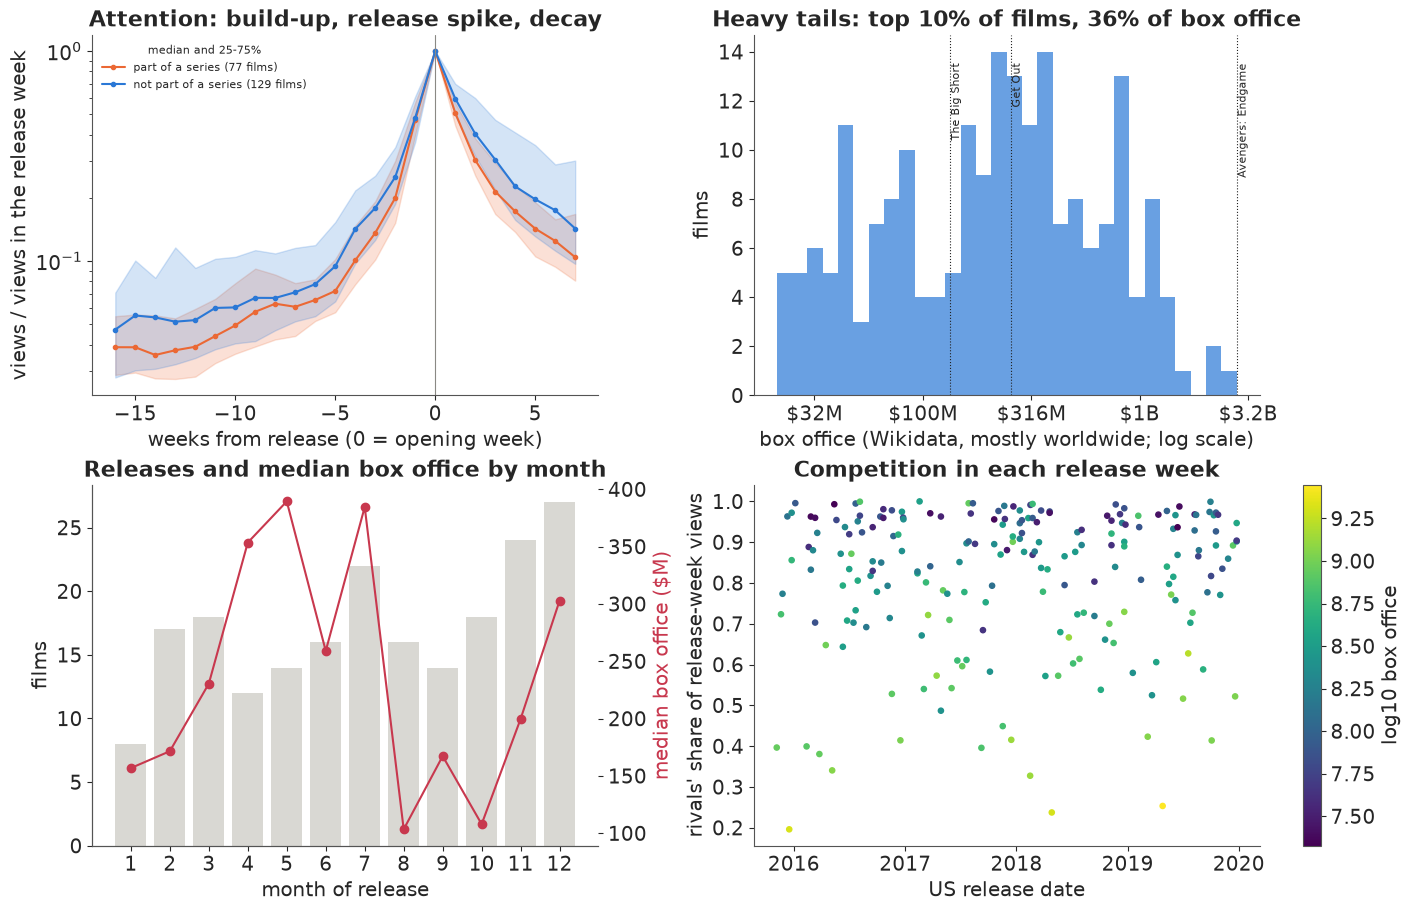

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
ax = axes[0, 0]
weeks = np.arange(-16, 8)
for ser, col, lab in [(True, ORANGE, "part of a series"), (False, BLUE, "not part of a series")]:
    q_ = rel[f.series.to_numpy() == ser][weeks].quantile([0.25, 0.5, 0.75])
    ax.fill_between(weeks, q_.loc[0.25], q_.loc[0.75], color=col, alpha=0.2)
    ax.plot(weeks, q_.loc[0.5], "o-", color=col, ms=3, label=f"{lab} ({(f.series == ser).sum()} films)")
ax.axvline(0, color=MUTED, lw=0.8)
ax.set(yscale="log", xlabel="weeks from release (0 = opening week)", ylabel="views / views in the release week",
       title="Attention: build-up, release spike, decay")
ax.legend(fontsize=8, title="median and 25-75%", title_fontsize=8)
ax = axes[0, 1]
ax.hist(np.log10(f.box_office_usd), bins=30, color=BLUE, alpha=0.7)
for t_ in ["Avengers: Endgame", "Get Out", "The Big Short"]:
    if (f.label == t_).any():
        v_ = np.log10(f.box_office_usd[f.label == t_].iloc[0])
        ax.axvline(v_, color=INK, lw=0.8, ls=":")
        ax.text(v_, ax.get_ylim()[1] * 0.92, " " + t_, rotation=90, va="top", fontsize=8)
ax.set_xticks([7.5, 8, 8.5, 9, 9.5], ["$32M", "$100M", "$316M", "$1B", "$3.2B"])
ax.set(xlabel="box office (Wikidata, mostly worldwide; log scale)", ylabel="films",
       title=f"Heavy tails: top 10% of films, {bo.sort_values().iloc[-F // 10:].sum() / bo.sum():.0%} of box office")
ax = axes[1, 0]
ax.bar(mon.index, mon.films, color=LIGHT, label="films released")
ax.set(xlabel="month of release", ylabel="films", xticks=range(1, 13))
ax2 = ax.twinx()
ax2.plot(mon.index, mon.median_bo, "o-", color=RED, label="median box office")
ax2.set_ylabel("median box office ($M)", color=RED)
ax2.grid(False)
ax.set_title("Releases and median box office by month")
ax = axes[1, 1]
sc_ = ax.scatter(f.release, rshare, c=np.log10(f.box_office_usd), cmap="viridis", s=14)
fig.colorbar(sc_, ax=ax, label="log10 box office")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set(xlabel="US release date", ylabel="rivals' share of release-week views",
       title="Competition in each release week");

Four real facts carry into everything below.

**Attention has a shape.** Eight weeks out, the median film draws about 6% of its release-week
views; four weeks out 13%; in the last week before release about half. It then decays at a median
of 0.26 on the log scale per week, a weekly drop of about a quarter, with a wide spread: some
films barely fade for six weeks, others lose a third a week. The alignment check guarantees that every earlier week draws fewer views than the release
week, and drops films whose attention peaked earlier, so this build-up describes the films that
pass it. It is real attention, and the real campaigns are part of it: views jump when a trailer
drops. Our simulator uses each film's own curve as the baseline that the simulated media add to,
so the planted media effect is incremental to whatever the real studios did, and part of the
shared ramp of Failure 2 below comes from the real campaigns' timing.

**Box office is heavy tailed** (De Vany & Walls 1999). The median film here took \$238M, the 5th
percentile \$30M and the 95th \$1.14B, and the top tenth of films took 36% of the total. The
sample leans to big films: Wikidata records box office for a minority of releases, mostly the
visible ones, and mostly as a worldwide figure.

**The calendar is crowded unevenly.** In the median film's release week, 87% of the views going to
films in this set went to its rivals; for a few films it was under half, for others nearly all.
December, November and July hold the most releases.

**The month a film opens in looks like a huge effect.** Median box office runs from about \$100M
for August and October releases to nearly \$390M for May and July ones. Some of that is demand -
summer and holidays - but Einav (2007) showed that studios place their strongest films in those
weeks, so the month also measures which films were put there. In the simulator below the planted
month effect is between -8% and +10%; anything larger that a cross-film comparison finds is
selection.

## B · Planting known effects

Each film $f$ is sold in ten markets $m$ with population shares $p_m$ from 20% down to 5%, over
weeks $k$ from 12 weeks before release to 3 weeks after (week 0 is the opening week). Spend
$s_{fmk}$ is in \$M. Its effect is a **goodwill stock** in the sense of Nerlove & Arrow (1962):

$$x_{fmk} = \log\Big(1 + \frac{s_{fmk}}{p_m \kappa (1 + \chi\, c_{fk})}\Big), \qquad
M_{fmk} = \lambda M_{fm,k-1} + x_{fmk}, \qquad \lambda = 0.75,$$

a concave weekly response (each further dollar in a week buys less, $\kappa = \$4$M a week
nationally), made dearer by **clutter** $c_{fk}$, the rivals' spend in the same calendar week
relative to its average ($\chi = 0.5$), and carried over with a half-life of 2.4 weeks: people
forget. Rivals' spend comes from every other film's standard campaign placed on the **real**
release calendar, so crowded weeks are the real crowded weeks.

Awareness combines the stock with each film's organic interest. Organic awareness at release $A_f$
is set from the film's real views in week -1 (from 13% to 59% between the 5th and 95th
percentiles), and its path before release follows the square root of the film's real views
relative to week -1. Each market scales that organic interest up or down ($\mu_{fm}$, sd 0.2), and
media adds to its cumulative hazard:

$$a_{fmk} = 1 - (1 - a^0_{fmk})^{e^{\mu_{fm} + \xi_{fmk}}}\, e^{-\beta M_{fmk}}, \qquad \beta = 0.30,$$

with $\xi$ a small persistent local buzz (AR(1), 0.7). A tracking survey of 400 people per market
and week measures awareness from week -12 to week -1.

**Exhibitors** book screens from tracking in weeks -4 to -2 and from the film's expected size: the
share of screens $\text{scr}_{fm} = \text{expit}(1.0 + 1.5\, \overline{\text{logit}\,
T}_{fm,-4..-2} + 0.6\, S_f + \zeta_{fm})$, $S_f$ the log expected gross (centred) and $\zeta$ the
exhibitors' own judgement (sd 0.2). Money spent after week -2 cannot move screens. Screens are a
**mediator**: spend raises tracking, tracking raises screens, screens raise the opening.

The **opening** in a market is

$$\log O_{fm} = \log \theta_f + \log p_m + \nu \log \frac{a_{fm0}}{A_f} + \eta \log
\text{scr}_{fm} + \text{season}_f - \rho\, \text{comp}_f + u_f + \varepsilon_{fm},$$

with $\nu = 1$ (opening proportional to awareness in the opening week) and $\eta = 0.8$, the
planted month effect, and the real competition in the release week, $\text{comp}_f = \log(1 +
\text{rival views} / \text{own views})$, at $\rho = 0.15$. After the opening the gross decays at a
film-specific rate $\delta_f$ set from the film's **real** attention decay, standing in for word
of mouth (median 0.66 on the log scale, a weekly drop of about half), and awareness after release
has a smaller effect ($\nu_P = 0.5$):

$$\log G_{fmw} = \log O_{fm} - \delta_f w + \nu_P \log(a_{fmw} / a_{fm0}) + g_{fmw}, \qquad w = 1..7,$$

plus a geometric tail. $\theta_f$ is calibrated so that each film's expected domestic gross under
the standard campaign is 0.4 of its real box office. The **studio's returns** are its rental share
of the gross, minus P&A:

$$R_f = \sum_w \pi_w G_{fw} - \sum_k s_{fk}, \qquad \pi_w = 0.60, 0.55, 0.50, 0.45, 0.40, \ldots,
0.35 \text{ on the tail}.$$

Real deals between studios and exhibitors vary by film and week; this declining schedule, with the
studio's share highest in the opening week, is an assumption, and it is one reason the opening
matters so much.

**How studios spend in this world.** A film's budget follows the studio's (noisy) forecast, $0.8\,
\hat G^{0.8}$, and bigger films start earlier: campaigns run 5 to 12 weeks by forecast rank, a
geometric ramp (30% more each week) into release, with 85% before release and 15% in weeks 1-3.
Market budgets carry some natural noise (log sd 0.1). Spend also **reacts**: at week -4, a film
tracking behind the norm for its forecast gets more money in weeks -3 to 0, and within the film
the late money tilts toward the markets tracking behind; after release, a film that opened above
expectations gets more. Finally, in a **timing test** a share of films assign each market at
random to one of four arms - a campaign four weeks longer, three weeks shorter, the standard one,
or random weekly flights - each with that market's usual pre-release total.

In [5]:
KW = np.arange(-12, 4)                          # spend weeks: 12 before release to 3 after
NK = len(KW)
J0 = int(np.flatnonzero(KW == 0)[0])
P_M = np.array([0.20, 0.15, 0.12, 0.10, 0.09, 0.08, 0.08, 0.07, 0.06, 0.05])   # market population shares
NM = len(P_M)
SHARE = np.array([0.60, 0.55, 0.50, 0.45, 0.40, 0.40, 0.40, 0.40])   # studio rental share, weeks 0-7
SHARE_TAIL = 0.35
N_SURVEY = 400
TRUE = dict(lam=0.75, betaA=0.30, kappa=4.0, chi=0.5, nu=1.0, eta=0.8, nuP=0.5, rho=0.15,
            z0=1.0, z1=1.5, z2=0.6, decision=(-4, -3, -2), sd_u=0.25, sd_eps=0.15, sd_g=0.10, sd_mkt=0.20,
            season={1: -0.08, 2: -0.05, 3: 0.0, 4: -0.03, 5: 0.08, 6: 0.10, 7: 0.10, 8: 0.0, 9: -0.08,
                    10: -0.03, 11: 0.08, 12: 0.10})
JD = np.flatnonzero(np.isin(KW, TRUE["decision"]))   # the exhibitors' booking window


def binom_ppf(u, p):
    return binom.ppf(u, N_SURVEY, p) / N_SURVEY


def stock(x, lam):
    """Geometric carryover along the last axis (weeks)."""
    out, a = np.empty_like(x), np.zeros(x.shape[:-1])
    for j in range(x.shape[-1]):
        a = lam * a + x[..., j]
        out[..., j] = a
    return out


def ramp(L, g=0.3, post_share=0.15):
    """The standard schedule's shape: a geometric ramp from week -L to 0, then weeks 1-3."""
    w = np.zeros(NK)
    pre = (KW >= -L) & (KW <= 0)
    w[pre] = np.exp(g * (KW[pre] + L))
    w[pre] *= (1 - post_share) / w[pre].sum()
    w[KW >= 1] = post_share * np.array([0.5, 0.3, 0.2])
    return w


def awareness(s, a0, clutter, th, bm=1.0):
    """Spend ($M) by film x market x week -> awareness and the media stock."""
    x = s / (P_M[None, :, None] * th["kappa"] * (1 + th["chi"] * clutter[:, None, :]))
    h = np.log1p(x) if th.get("resp", "log1p") == "log1p" else 2.0 * x ** 3 / (1 + x ** 3)   # concave or S-shaped
    M = stock(h, th["lam"])
    return 1 - (1 - a0) * np.exp(-th["betaA"] * bm * M), M


def gross_paths(fp, s, th, clutter, noise=None):
    """Expected (noise=None) or simulated weekly gross by film x market x week 0..7, with screens,
    awareness and the stock."""
    Fn = s.shape[0]
    mk = noise["mk"] if noise is not None else np.zeros((Fn, NM))
    ar = noise["ar"] if noise is not None else 0.0
    a0m = 1 - (1 - fp["a0"][:, None, :]) ** np.exp(mk[:, :, None] + ar)      # market interest scales the hazard
    bm = np.exp(th.get("het", 0.0) * mk)[:, :, None] if noise is not None else 1.0   # part E: media by market
    aw, M = awareness(s, a0m, clutter, th, bm)
    if noise is not None and noise.get("surv") is not None:
        Td = np.clip(binom_ppf(noise["surv"][:, :, JD], aw[:, :, JD]), 0.5 / N_SURVEY, 1 - 0.5 / N_SURVEY)
    else:                                                           # no survey error (expected, or realised film)
        Td = aw[:, :, JD]
    zs = noise["zs"] if noise is not None else 0.0
    scr = expit(th["z0"] + th["z1"] * logit(Td).mean(-1) + th["z2"] * fp["lsize"][:, None] + zs)
    awg = np.concatenate([aw[:, :, J0:], np.repeat(aw[:, :, -1:], 8 - (NK - J0), 2)], 2)   # weeks 0..7
    bm0 = bm[:, :, 0] if np.ndim(bm) else bm
    for i, w in enumerate(range(NK - J0, 8)):                      # after the last spend week the stock decays
        awg[:, :, w] = 1 - (1 - a0m[:, :, -1]) * np.exp(-th["betaA"] * bm0 * M[:, :, -1] * th["lam"] ** (i + 1))
    u = noise["u"][:, None] if noise is not None else 0.0
    eps = noise["eps"] if noise is not None else 0.0
    logO = (np.log(fp["theta"])[:, None] + np.log(P_M)[None] + th["nu"] * np.log(awg[:, :, 0] / fp["A"][:, None])
            + th["eta"] * np.log(scr) + fp["season"][:, None] - th["rho"] * fp["comp"][:, None] + u + eps)
    w = np.arange(8)
    logG = logO[:, :, None] - fp["delta"][:, None, None] * w + th["nuP"] * np.log(awg / awg[:, :, :1])
    if noise is not None and noise.get("g") is not None:
        logG = logG + noise["g"] * (w > 0)
    elif noise is not None:                                         # realised film: average over later weeks' noise
        logG = logG + 0.5 * th["sd_g"] ** 2 * (w > 0)
    else:                                                           # the mean of the lognormal noise
        logG = logG + 0.5 * (th["sd_u"] ** 2 + th["sd_eps"] ** 2) + 0.5 * th["sd_g"] ** 2 * (w > 0)
    return np.exp(logG), scr, aw, M


def returns(G, fp, spend_k):
    """Studio returns: rental share x gross (weeks 0-7 plus a geometric tail) minus spend; also total gross."""
    Gw = G.sum(1)
    r = np.exp(-fp["delta"])
    tail = Gw[:, -1] * r / (1 - r)
    return (Gw * SHARE).sum(1) + SHARE_TAIL * tail - spend_k.sum(1), Gw.sum(1) + tail


def calibrate(f, VW, th=TRUE):
    """Film parameters from the real data, the rivals' clutter on the real calendar, and theta."""
    v = VW.loc[:, -12:-1].to_numpy().astype(float)
    shape = np.sqrt((v + 50) / (VW[-1].to_numpy()[:, None] + 50)).clip(0.02, 1.3)
    lv = np.log(f.v_m1.to_numpy() + 1)
    A = expit(-0.6 + 0.8 * (lv - lv.mean()) / lv.std())                        # organic awareness at release
    fp = dict(F=len(f), A=A, a0=np.concatenate([A[:, None] * shape, np.repeat(A[:, None], NK - 12, 1)], 1).clip(0.01, 0.95),
              delta=np.clip(0.35 + 1.2 * f.att_decay.to_numpy(), 0.25, 1.2), comp=f.comp.to_numpy(),
              season=np.array([th["season"][m] for m in f.month]), cal0=f.cal0.to_numpy(),
              bo=f.box_office_usd.to_numpy() / 1e6, series=f.series.to_numpy().astype(bool))
    Fn = fp["F"]
    fp["fc"] = 0.4 * fp["bo"]                                                  # expected domestic gross
    fp["lsize"] = np.log(fp["fc"]) - np.median(np.log(fp["fc"]))
    rank = (np.argsort(np.argsort(fp["fc"])) + 0.5) / Fn
    fp["L"] = np.round(5 + 7 * rank).astype(int)
    fp["budget"] = 0.8 * fp["fc"] ** 0.8
    sched = np.stack([fp["budget"][i] * ramp(fp["L"][i]) for i in range(Fn)])
    R = np.zeros(fp["cal0"].max() + 20)
    for i in range(Fn):
        np.add.at(R, fp["cal0"][i] + KW + 12, sched[i])
    fp["clutter"] = (R[fp["cal0"][:, None] + KW[None] + 12] - sched) / R[R > 0].mean()   # rivals' spend, own removed
    fp["theta"] = np.ones(Fn)
    G, *_ = gross_paths(fp, sched[:, None, :] * P_M[None, :, None], th, fp["clutter"])
    fp["theta"] = 0.4 * fp["bo"] / returns(G, fp, sched)[1]
    fp["sched_std"] = sched
    return fp


def make_noise(Fn, seed, th=TRUE, ar_sd=0.08):
    rs = np.random.default_rng(seed)
    inn = rs.normal(0, ar_sd, (Fn, NM, NK))
    ar = np.zeros((Fn, NM, NK))
    ar[:, :, 0] = inn[:, :, 0] / np.sqrt(1 - 0.7 ** 2)
    for j in range(1, NK):
        ar[:, :, j] = 0.7 * ar[:, :, j - 1] + inn[:, :, j]
    return dict(u=rs.normal(0, th["sd_u"], Fn), eps=rs.normal(0, th["sd_eps"], (Fn, NM)),
                g=rs.normal(0, th["sd_g"], (Fn, NM, 8)), mk=rs.normal(0, th["sd_mkt"], (Fn, NM)),
                surv=rs.random((Fn, NM, NK)), fc=rs.normal(0, 0.25, Fn), nat=rs.normal(0, 0.1, (Fn, NM, NK)),
                rsurv=rs.random((Fn, NM, NK)), zs=rs.normal(0, 0.2, (Fn, NM)), ar=ar)


def observational(fp, nz, th=TRUE, test_level="market", test_frac=0.0, seed=0, reactive=True, tilt_k=1.5,
                  nat_sd=0.1):
    """One world: the studios' spending habits, optionally a randomised timing test in a share of films."""
    Fn = fp["F"]
    fcast = fp["fc"] * np.exp(nz["fc"])                                         # the studio's noisy forecast
    budget = 0.8 * fcast ** 0.8
    L = np.round(5 + 7 * (np.argsort(np.argsort(fcast)) + 0.5) / Fn).astype(int)
    base = np.stack([budget[i] * ramp(L[i]) for i in range(Fn)])
    s = base[:, None, :] * P_M[None, :, None] * np.exp(nz["nat"] * nat_sd / 0.1 - nat_sd ** 2 / 2)
    rs = np.random.default_rng(seed)
    in_test = rs.random(Fn) < test_frac
    arm = np.zeros((Fn, NM), int)
    for i in np.flatnonzero(in_test):
        arm[i] = rs.permutation(np.resize([-1, 0, 1, 2], NM)) if test_level == "market" else rs.integers(-1, 3)
        for m in range(NM):
            tot = s[i, m, KW <= 0].sum()
            if arm[i, m] == 2:                                                  # random weekly flights
                if test_level == "market" or m == 0:
                    fl = rs.lognormal(0, 0.6, (KW <= 0).sum())
                wv = s[i, m, KW <= 0] * fl
            else:                                                               # 4 weeks longer / standard / 3 shorter
                wv = ramp(int(np.clip(L[i] - {-1: -4, 0: 0, 1: 3}[arm[i, m]], 3, 12)), post_share=0.0)[KW <= 0]
            s[i, m, KW <= 0] = tot * wv / wv.sum()
    clutter = fp["clutter"]
    _, _, aw0, _ = gross_paths(fp, s, th, clutter, noise=nz)
    j4 = int(np.flatnonzero(KW == -4)[0])
    track = np.clip(binom_ppf(nz["surv"], aw0), 0.5 / N_SURVEY, 1 - 0.5 / N_SURVEY)
    nat4 = (track[:, :, j4] * P_M).sum(1)
    X = np.column_stack([np.ones(Fn), np.log(fcast)])
    sur = logit(nat4) - X @ np.linalg.lstsq(X, logit(nat4), rcond=None)[0]     # tracking surprise at week -4
    late = (KW >= -3) & (KW <= 0)
    if reactive:                                                                # push the laggards late ...
        s[:, :, late] *= np.clip(np.exp(-0.8 * sur), 0.6, 1.7)[:, None, None]
        lt = logit(track[:, :, j4])                                             # ... toward their weak markets
        tilt = np.clip(np.exp(-tilt_k * (lt - (lt * P_M).sum(1, keepdims=True))),
                       0.5 if tilt_k <= 1.5 else 0.33, 2.0 if tilt_k <= 1.5 else 3.0)
        tilt /= (tilt * P_M).sum(1, keepdims=True)
        tilt[in_test] = 1.0                                                     # test films keep their plan
        s[:, :, late] *= tilt[:, :, None]
    G1, *_ = gross_paths(fp, s, th, clutter, noise=nz)
    O = G1[:, :, 0].sum(1)
    surO = np.log(O) - X @ np.linalg.lstsq(X, np.log(O), rcond=None)[0]
    if reactive:                                                                # ... and double down on hits
        s[:, :, KW >= 1] *= np.clip(np.exp(surO), 0.3, 3.0)[:, None, None]
    G, scr, aw, M = gross_paths(fp, s, th, clutter, noise=nz)
    track = np.clip(binom_ppf(nz["surv"], aw), 0.5 / N_SURVEY, 1 - 0.5 / N_SURVEY)
    ret, tot = returns(G, fp, s.sum(1))
    return dict(s=s, G=G, scr=scr, aw=aw, M=M, track=track[:, :, :12], fcast=fcast, budget=budget, L=L,
                in_test=in_test, arm=arm, ret=ret, tot=tot)


fp = calibrate(f, VW)
none = np.zeros_like(fp["sched_std"])
G_std, *_ = gross_paths(fp, fp["sched_std"][:, None, :] * P_M[None, :, None], TRUE, fp["clutter"])
G_0, *_ = gross_paths(fp, none[:, None, :], TRUE, fp["clutter"])
R_std, tot_std = returns(G_std, fp, fp["sched_std"])
R_0, tot_0 = returns(G_0, fp, none)
print("organic awareness at release A, 5/50/95%: " + " / ".join(f"{v:.2f}" for v in np.quantile(fp["A"], [0.05, 0.5, 0.95])))
print("gross decay delta (log per week), 5/50/95%: " + " / ".join(f"{v:.2f}" for v in np.quantile(fp["delta"], [0.05, 0.5, 0.95])))
print("rivals' clutter in the release week, 5/50/95%: "
      + " / ".join(f"{v:.2f}" for v in np.quantile(fp["clutter"][:, J0], [0.05, 0.5, 0.95])))
print("standard P&A budget ($M), 5/50/95%: " + " / ".join(f"{v:.0f}" for v in np.quantile(fp["budget"], [0.05, 0.5, 0.95]))
      + f"; budget / expected gross, median {np.median(fp['budget'] / tot_std):.2f}")
print(f"expected gross with the standard campaign / with none, median x{np.median(tot_std / tot_0):.2f}; "
      f"the campaign pays for itself (returns above no campaign) for {np.mean(R_std > R_0):.0%} of films")

organic awareness at release A, 5/50/95%: 0.13 / 0.37 / 0.59
gross decay delta (log per week), 5/50/95%: 0.32 / 0.66 / 0.83
rivals' clutter in the release week, 5/50/95%: 0.44 / 0.97 / 1.41
standard P&A budget ($M), 5/50/95%: 6 / 31 / 108; budget / expected gross, median 0.32
expected gross with the standard campaign / with none, median x2.59; the campaign pays for itself (returns above no campaign) for 61% of films


The standard campaign costs about a third of a film's expected gross in the median (P&A for a wide
release is commonly a large share of the gross) and multiplies the gross by about 2.6. As a whole
it pays for itself - the extra rental beats the spend - for 61% of films. That is the average
dollar; part C shows that the marginal dollar is another matter, and that where it is spent
decides whether it earns its keep.

Here is one film in the world we will use for decisions, with the studio's usual habits switched
on.

Get Out: budget $23.8M over 8 weeks, gross $87M, returns $25M; test film London Has Fallen: arms by market [-1, -1, 2, -1, 0, 2, 1, 0, 1, 0] (-1 longer, 0 standard, 1 shorter, 2 random flights)
timing test in 94 of 206 films


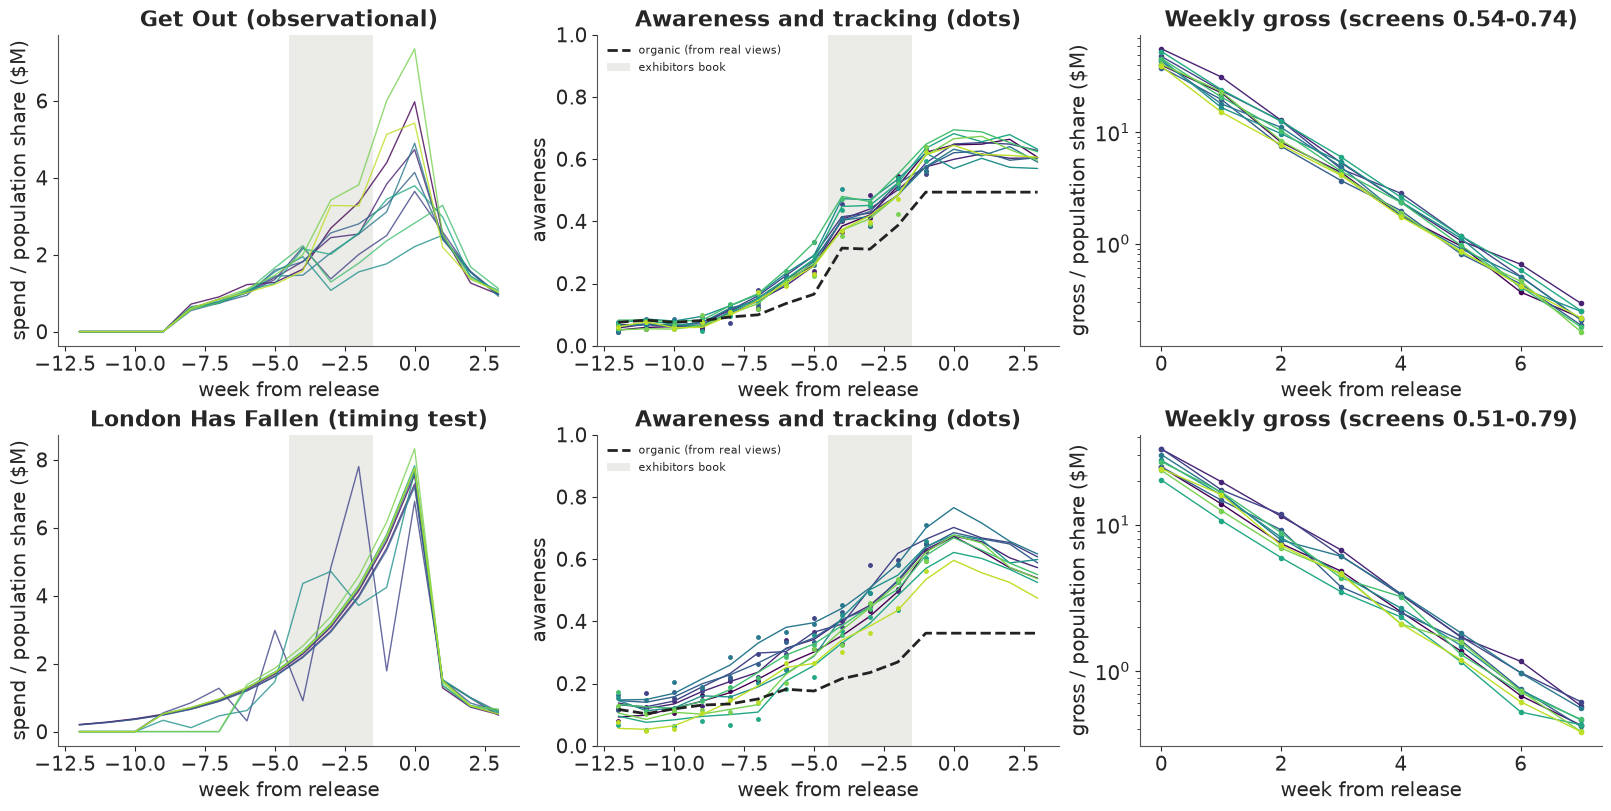

In [6]:
nz_dec = make_noise(F, 101)
ob = observational(fp, nz_dec, seed=201)                                    # the decision world, no test
obT = observational(fp, nz_dec, test_frac=0.4, seed=201)                    # the same world with a timing test
i_demo = int(np.flatnonzero(f.label.to_numpy() == "Get Out")[0])
tid = int(np.flatnonzero(obT["in_test"] & (np.abs(np.log(fp["fc"] / fp["fc"][i_demo])) < 0.3))[0])
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for row, (o, i, lab) in enumerate([(ob, i_demo, "observational"), (obT, tid, "timing test")]):
    ax = axes[row, 0]
    for m in range(NM):
        ax.plot(KW, o["s"][i, m] / P_M[m], color=plt.cm.viridis(m / NM), lw=1, alpha=0.8)
    ax.axvspan(-4.5, -1.5, color=LIGHT, alpha=0.5, lw=0)
    ax.set(xlabel="week from release", ylabel="spend / population share ($M)",
           title=f"{f.label.iloc[i]} ({lab})")
    ax = axes[row, 1]
    for m in range(NM):
        c = plt.cm.viridis(m / NM)
        ax.plot(KW, o["aw"][i, m], color=c, lw=1)
        ax.plot(KW[:12], o["track"][i, m], "o", color=c, ms=2.5)
    ax.plot(KW, fp["a0"][i], color=INK, lw=2, ls="--", label="organic (from real views)")
    ax.axvspan(-4.5, -1.5, color=LIGHT, alpha=0.5, lw=0, label="exhibitors book")
    ax.set(xlabel="week from release", ylabel="awareness", ylim=(0, 1), title="Awareness and tracking (dots)")
    ax.legend(fontsize=8)
    ax = axes[row, 2]
    for m in range(NM):
        ax.plot(np.arange(8), o["G"][i, m] / P_M[m], "o-", color=plt.cm.viridis(m / NM), ms=3, lw=1)
    ax.set(yscale="log", xlabel="week from release", ylabel="gross / population share ($M)",
           title=f"Weekly gross (screens {o['scr'][i].min():.2f}-{o['scr'][i].max():.2f})")
print(f"{f.label.iloc[i_demo]}: budget ${ob['s'][i_demo].sum():.1f}M over {ob['L'][i_demo]} weeks, gross "
      f"${ob['tot'][i_demo]:.0f}M, returns ${ob['ret'][i_demo]:.0f}M; test film {f.label.iloc[tid]}: arms by market "
      f"{obT['arm'][tid].tolist()} (-1 longer, 0 standard, 1 shorter, 2 random flights)")
print(f"timing test in {obT['in_test'].sum()} of {F} films")

The top row is the observational habit: every market follows the same ramp into release, with a
little noise and a late tilt toward the markets that tracked behind at week -4. Awareness (lines)
rises above the organic path (dashed), and the tracking survey (dots) measures it with an error of
a couple of points. The bottom row is a film in the timing test: some markets start four weeks
earlier, some three weeks later, some spend in random bursts, all with their usual total.

## C · What each kind of data can identify

We need many estimates in many worlds, so this part uses fast estimators - least squares and
profiled likelihoods in NumPy - over five simulated worlds that share the real films and differ in
their noise. Each world is generated four ways: the studios' habits, the same with a market timing
test in 40% of films, with a timing test that assigns one arm to a whole film, and without
reactive spend.

### C1 · The truth: what an extra dollar buys, and when

First the answer every estimator is chasing. At each film's own schedule, we add \$0.5M spread
over one bucket of weeks and compute, with the simulator's expected values, the extra opening
gross and the extra studio returns per dollar, and the share of the extra opening that comes
through screens (the part that disappears if screens are held at their old level).

In [7]:
BUCKETS = {"early (-12..-7)": (KW >= -12) & (KW <= -7), "mid (-6..-3)": (KW >= -6) & (KW <= -3),
           "late (-2..0)": (KW >= -2) & (KW <= 0), "post (1..3)": KW >= 1}
PRE_B = list(BUCKETS)[:3]
LAMS = np.round(np.arange(0.0, 0.96, 0.05), 2)


def xeff(s):
    return np.log1p(s / (P_M[None, :, None] * TRUE["kappa"] * (1 + TRUE["chi"] * fp["clutter"][:, None, :])))


def truth_marginal(o, eps=0.5):
    s = o["s"]
    G, scr, *_ = gross_paths(fp, s, TRUE, fp["clutter"])
    r, _ = returns(G, fp, s.sum(1))
    out = {}
    for b, mask in BUCKETS.items():
        ds = np.zeros_like(s)
        ds[:, :, mask] = eps / mask.sum() * P_M[None, :, None]
        G1, scr1, *_ = gross_paths(fp, s + ds, TRUE, fp["clutter"])
        r1, _ = returns(G1, fp, (s + ds).sum(1))
        dO = G1[:, :, 0].sum(1) - G[:, :, 0].sum(1)
        dO_fixed = (G1[:, :, 0] * (scr / scr1) ** TRUE["eta"]).sum(1) - G[:, :, 0].sum(1)
        via = 1 - dO_fixed / np.maximum(dO, 1e-9)
        out[b] = dict(opening=np.mean(dO / eps), returns=np.mean((r1 - r) / eps),
                      via_screens=np.mean(via) if np.mean(dO) > 1e-6 else np.nan)   # no opening effect: no share
    return out


t0 = time.time()
WORLDS = []
for r in range(5):
    nz = make_noise(F, 100 + r)
    WORLDS.append(dict(ob=observational(fp, nz, seed=200 + r), obT=observational(fp, nz, test_frac=0.4, seed=200 + r),
                       obF=observational(fp, nz, test_frac=1.0, test_level="film", seed=300 + r),
                       obN=observational(fp, nz, seed=200 + r, reactive=False)))
tm = pd.DataFrame([{"bucket": b, **v} for W_ in WORLDS for b, v in truth_marginal(W_["ob"]).items()])
TRUTH_TAB = tm.groupby("bucket", sort=False).mean()
print(f"5 worlds x 4 versions in {time.time() - t0:.1f} s")
print("truth, per extra $1 at each film's own schedule (mean over films and worlds):")
print(TRUTH_TAB.rename(columns={"opening": "opening $", "returns": "studio returns $",
                                "via_screens": "share via screens"}).round(2).to_string())

5 worlds x 4 versions in 3.9 s
truth, per extra $1 at each film's own schedule (mean over films and worlds):
                 opening $  studio returns $  share via screens
bucket                                                         
early (-12..-7)       0.43             -0.49               0.80
mid (-6..-3)          1.16              0.35               0.78
late (-2..0)          0.54             -0.40               0.21
post (1..3)           0.00             -0.86                NaN


At the schedules the studios ran, a dollar spent in weeks -6 to -3 brings \$1.16 of opening gross
and **\$0.35 of studio returns**, net of its own cost. A dollar in weeks -12 to -7 brings 43 cents
of opening and loses 49 cents: at a carryover of 0.75 a week, less than a fifth of its stock is
left after six weeks of forgetting, and what reaches the opening comes mostly through the screens
it helped book. A dollar in the last three weeks brings 54 cents and loses 40: it reaches the
opening at full strength but mostly misses the exhibitors (only week -2 is in their booking
window), and the studios' schedules already put the most money in those weeks, so its weekly
response is flattest there. A dollar after release brings no opening (by construction) and very
little later, and loses 86 cents.

About 80% of the opening gain from early money, and 78% from mid-campaign money, runs **through
screens**, against a fifth for the last weeks; the mid-campaign bucket ends inside the booking
window. This is a first, marginal answer: at the studios' schedules, which already put over half
the budget in the last three weeks, the next dollar belongs in weeks -6 to -3. It is not the
optimum. Part F shows that the best schedule still keeps about two fifths of the money late, with
a second peak in the opening week, where the rental share is highest.

### C2 · The naive model: line the films up by weeks to release

The analyst's first model has one row per film: log national opening on the log of spend in each
bucket of weeks,

$$\log O_f = b_0 + \sum_{\text{bucket}} b_j \log(S_{fj} + 0.1) + \epsilon_f,$$

turned into dollars of opening per extra dollar in each bucket. Variants add log screens, the
studio's own forecast, or remove reactive spend.

In [8]:
def naive_crossfilm(o, controls=(), elasticity=False):
    O = o["G"][:, :, 0].sum(1)
    sb = {b: o["s"][:, :, m].sum((1, 2)) for b, m in BUCKETS.items() if b in PRE_B}
    X = [np.ones(F)] + [np.log(v + 0.1) for v in sb.values()]
    if "screens" in controls:
        X.append(np.log((o["scr"] * P_M).sum(1)))
    if "forecast" in controls:
        X.append(np.log(o["fcast"]))
    b = np.linalg.lstsq(np.column_stack(X), np.log(O), rcond=None)[0]
    if elasticity:
        return dict(zip(sb, b[1:4]))
    return {k: float(np.mean(b[1 + i] * O / (v + 0.1))) for i, (k, v) in enumerate(sb.items())}


rows = []
for r, W_ in enumerate(WORLDS):
    for lab, ctl, key in [("naive cross-film", (), "ob"), ("+ log screens", ("screens",), "ob"),
                          ("+ studio forecast", ("forecast",), "ob"), ("no reactive spend", (), "obN"),
                          ("no reactive spend, + forecast", ("forecast",), "obN")]:
        for b, v in naive_crossfilm(W_[key], ctl).items():
            rows.append(dict(model=lab, bucket=b, rep=r, value=v))
NAIVE = pd.DataFrame(rows)
nt = NAIVE.groupby(["model", "bucket"], sort=False).value.agg(["mean", "min", "max"]).unstack("bucket")
nt = nt.swaplevel(axis=1)[[(b, s_) for b in PRE_B for s_ in ("mean", "min", "max")]]
print("opening $ per extra $1, cross-film OLS (mean, min, max over 5 worlds); truth "
      + ", ".join(f"{b} {TRUTH_TAB.loc[b, 'opening']:.2f}" for b in PRE_B))
print(nt.round(1).to_string())
el_n = pd.DataFrame([naive_crossfilm(W_["ob"], elasticity=True) for W_ in WORLDS]).mean()
print("naive cross-film elasticities b (log opening on log(spend + $0.1M)), mean over worlds: "
      + ", ".join(f"{k} {v:.2f}" for k, v in el_n.items()) + f"; films with no spend in weeks -12..-7: "
      f"{np.mean([(W_['ob']['s'][:, :, BUCKETS[PRE_B[0]]].sum((1, 2)) == 0).mean() for W_ in WORLDS]):.0%}")
ob_s = WORLDS[0]["ob"]
print(f"world 1: correlation of log forecast with log total spend {np.corrcoef(np.log(ob_s['fcast']), np.log(ob_s['s'].sum((1, 2))))[0, 1]:.2f}, "
      f"with campaign length {np.corrcoef(np.log(ob_s['fcast']), ob_s['L'])[0, 1]:.2f}")

opening $ per extra $1, cross-film OLS (mean, min, max over 5 worlds); truth early (-12..-7) 0.43, mid (-6..-3) 1.16, late (-2..0) 0.54
bucket                        early (-12..-7)            mid (-6..-3)            late (-2..0)          
                                         mean  min   max         mean   min  max         mean  min  max
model                                                                                                  
naive cross-film                         10.5  5.4  13.9          7.1   5.8  8.9         -1.2 -1.5 -0.8
+ log screens                             9.4  3.0  12.6          6.4   5.2  7.9         -0.9 -1.0 -0.7
+ studio forecast                         7.2  1.4  12.6         -2.2  -8.5  2.4          0.5 -0.5  1.2
no reactive spend                         7.7  2.5  11.9          1.0  -3.8  5.2          2.1 -0.5  4.6
no reactive spend, + forecast             4.8  1.8   8.1         -5.1 -13.4  0.1         -0.7 -5.2  2.0
naive cross-film elasticities b 

**Failure 1: the naive model reads budget selection as media effect, and gets the timing
backwards.** It says an extra dollar in weeks -12 to -7 brings \$10.5 of opening (5.4-13.9 across
worlds), 24 times the truth, and an extra dollar in the last three weeks *loses* \$1.2. Two habits
make those numbers. Big films get big budgets and start earlier (the log forecast correlates 0.99
with log spend, and 0.98 with campaign length), so "spent a lot early" is a marker for "big film".
And laggards get a late push, so late money marks films that were tracking badly. Taking the
reactive spend away removes the negative sign (late \$2.1) but leaves early money at \$7.7. The
size of the dollar figures depends partly on the \$0.1M offset in the log: a fifth of films spend
nothing before week -6, so their conversion divides by the offset. The elasticities themselves are
wrong in the same direction: 0.29 early, 1.21 mid and -0.40 late, against true elasticities of
about 0.02, 0.22 and 0.21 (part C4). Adding the studio's forecast, the obvious control, leaves no
stable answer: early from 1.4 to 12.6, mid from -8.5 to 2.4 across worlds. With one opening per
film and budgets set from a noisy forecast of the film's size, a cross-film regression cannot
separate timing from size: E104's random-intercept trap in its simplest form. Adding log screens
(the mediator) shrinks the numbers a little and fixes nothing.

### C3 · Tracking: weekly outcomes before the release

The opening is one number per film, but tracking is weekly. Awareness is linear in the stock on a
convenient scale: $\log(1 - a_{fmk}) = \log(1 - a^0_{fmk}) - \beta M_{fmk}$, up to the market
scaling of organic interest. So we can regress $\log(1 - T_{fmk})$ on the stock, profiling
$\lambda$ over a grid of steps of 0.05, with different amounts of the variation:

| design | outcome | variation used |
|---|---|---|
| national, pooled | national tracking | all film-weeks pooled, at the true $\lambda$ |
| national, film and week effects | national tracking | the usual panel fix, $\lambda$ profiled |
| within film, market by week | tracking by market | how one market's spend differed from the film's other markets in the same week (film-market and film-week effects removed); studios' habits, or films in the timing test |
| one opening per film | log national opening | the stock at release, with the log forecast; studios' habits, or a test that randomises whole films |

In [9]:
def stock_nat(o):
    return xeff(o["s"].sum(1)[:, None, :] * P_M[None, :, None])[:, 0, :]


def profile(y, X, demean):
    """Least squares of y on -beta * demean(stock(X, lambda)), lambda profiled over LAMS."""
    best = None
    for lam in LAMS:
        Ms = demean(stock(X, lam)[..., :12])
        b = -(Ms * y).sum() / (Ms * Ms).sum()
        sse = ((y + b * Ms) ** 2).sum()
        if best is None or sse < best[0]:
            best = (sse, lam, b)
    return best[1], float(best[2])


def dm_fw(a):                                    # film and week effects (film x week arrays)
    return a - a.mean(1, keepdims=True) - a.mean(0, keepdims=True) + a.mean()


def dm_fm_fw(a):                                 # film x market and film x week effects (film x market x week)
    return a - a.mean(1, keepdims=True) - a.mean(2, keepdims=True) + a.mean((1, 2), keepdims=True)


def national_pooled(o):
    y = np.log(1 - (o["track"] * P_M[None, :, None]).sum(1))
    M = stock(stock_nat(o), TRUE["lam"])[:, :12]
    return float(-((M - M.mean()) * (y - y.mean())).sum() / ((M - M.mean()) ** 2).sum())


def national_fe(o):
    y = dm_fw(np.log(1 - (o["track"] * P_M[None, :, None]).sum(1)))
    return profile(y, stock_nat(o), dm_fw)


def within_market(o, films=None):
    films = np.arange(F) if films is None else films
    y = dm_fm_fw(np.log(1 - o["track"][films]))
    return profile(y, xeff(o["s"])[films], dm_fm_fw)


def opening_only(o):
    O = np.log(o["G"][:, :, 0].sum(1))
    X = stock_nat(o)
    best = None
    for lam in LAMS:
        Z = np.column_stack([np.ones(F), stock(X, lam)[:, J0], np.log(o["fcast"])])
        b = np.linalg.lstsq(Z, O, rcond=None)[0]
        sse = ((O - Z @ b) ** 2).sum()
        if best is None or sse < best[0]:
            best = (sse, lam, b[1])
    return best[1], float(best[2])


rows = []
for r, W_ in enumerate(WORLDS):
    tf = np.flatnonzero(W_["obT"]["in_test"])
    rows += [dict(design="national tracking, pooled (beta at the true lambda)", rep=r, lam=np.nan,
                  beta=national_pooled(W_["ob"])),
             dict(design="national tracking, film + week effects", rep=r, **dict(zip(["lam", "beta"], national_fe(W_["ob"])))),
             dict(design="national tracking, film + week effects, film-level test", rep=r,
                  **dict(zip(["lam", "beta"], national_fe(W_["obF"])))),
             dict(design="one opening per film, studios' habits", rep=r, **dict(zip(["lam", "beta"], opening_only(W_["ob"])))),
             dict(design="one opening per film, film-level test", rep=r, **dict(zip(["lam", "beta"], opening_only(W_["obF"])))),
             dict(design="market x week within film, studios' habits", rep=r,
                  **dict(zip(["lam", "beta"], within_market(W_["ob"])))),
             dict(design="market x week within film, market timing test", rep=r,
                  **dict(zip(["lam", "beta"], within_market(W_["obT"], tf))))]
TRK = pd.DataFrame(rows)
print(f"truth: lambda {TRUE['lam']}, beta {TRUE['betaA']} (the opening-only beta is on another scale)")
print(TRK.groupby("design", sort=False)[["lam", "beta"]].agg(["mean", "min", "max"]).round(2).to_string())

truth: lambda 0.75, beta 0.3 (the opening-only beta is on another scale)
                                                          lam              beta            
                                                         mean   min   max  mean   min   max
design                                                                                     
national tracking, pooled (beta at the true lambda)       NaN   NaN   NaN  0.42  0.42  0.43
national tracking, film + week effects                   0.95  0.95  0.95  0.22  0.22  0.22
national tracking, film + week effects, film-level test  0.91  0.90  0.95  0.25  0.23  0.26
one opening per film, studios' habits                    0.82  0.30  0.95 -0.00 -0.06  0.13
one opening per film, film-level test                    0.70  0.20  0.95 -0.01 -0.05  0.11
market x week within film, studios' habits               0.43  0.40  0.50  0.18  0.17  0.19
market x week within film, market timing test            0.74  0.70  0.75  0.30  0.28  0.31


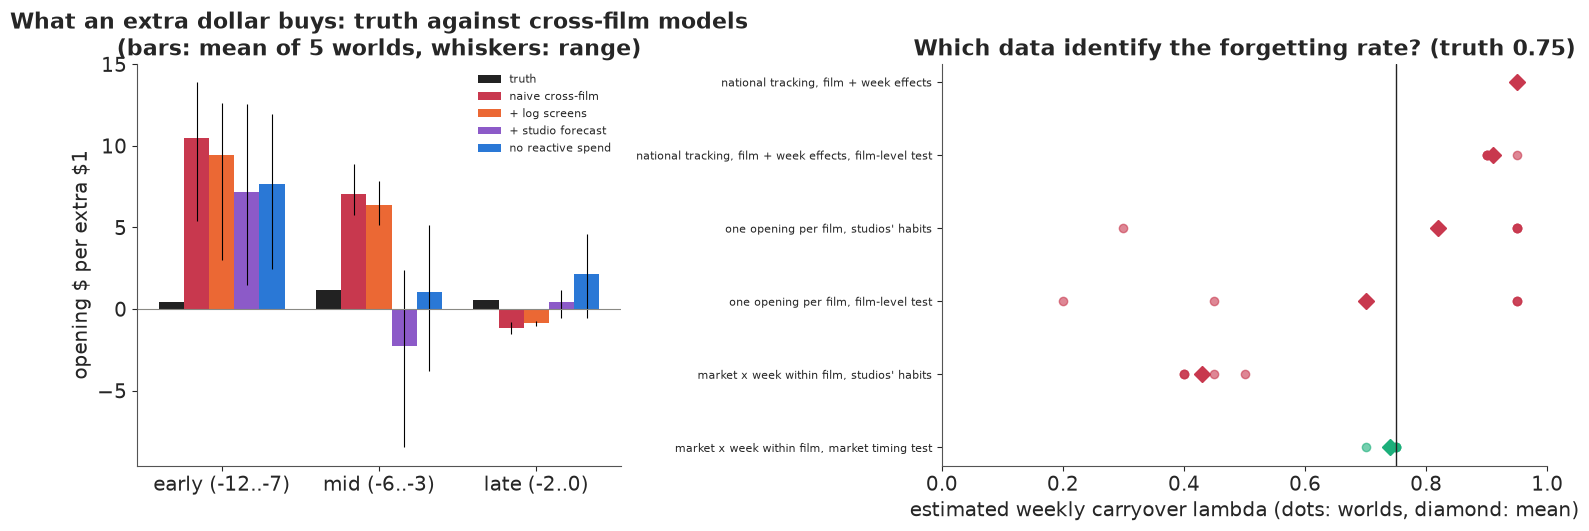

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw=dict(width_ratios=[1, 1.25]))
ax = axes[0]
xx = np.arange(3)
for k, (lab, col) in enumerate([("truth", INK), ("naive cross-film", RED), ("+ log screens", ORANGE),
                                ("+ studio forecast", PURPLE), ("no reactive spend", BLUE)]):
    if lab == "truth":
        v, lo, hi = TRUTH_TAB.loc[PRE_B, "opening"].to_numpy(), None, None
    else:
        g_ = NAIVE[NAIVE.model == lab].groupby("bucket", sort=False).value
        v, lo, hi = g_.mean()[PRE_B].to_numpy(), g_.min()[PRE_B].to_numpy(), g_.max()[PRE_B].to_numpy()
    ax.bar(xx + (k - 2) * 0.16, v, 0.16, color=col, label=lab,
           yerr=None if lo is None else np.vstack([v - lo, hi - v]), error_kw=dict(lw=0.8))
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xticks(xx, PRE_B)
ax.set(ylabel="opening \\$ per extra \\$1", title="What an extra dollar buys: truth against cross-film models\n(bars: mean of 5 worlds, whiskers: range)")
ax.legend(fontsize=8)
ax = axes[1]
des = TRK.design.unique()[1:]
for k, d_ in enumerate(des):
    v = TRK[TRK.design == d_].lam
    good = abs(v.mean() - TRUE["lam"]) < 0.06 and v.max() - v.min() < 0.15
    ax.plot(v, np.full(len(v), -k), "o", color=AQUA if good else RED, alpha=0.6)
    ax.plot(v.mean(), -k, "D", color=AQUA if good else RED, ms=8)
ax.axvline(TRUE["lam"], color=INK, lw=1)
ax.set_yticks(-np.arange(len(des)), des, fontsize=8)
ax.set(xlabel="estimated weekly carryover lambda (dots: worlds, diamond: mean)", xlim=(0, 1),
       title="Which data identify the forgetting rate? (truth 0.75)");

**Failure 2: national tracking reads the shared ramp as media.** Pooled over film-weeks, the media
coefficient is 0.42 against a true 0.30, at the true $\lambda$: every film's organic attention
rises into release just as its spend does. Film and week effects remove a common ramp, but not the
fact that bigger films run longer campaigns and also build more interest; with $\lambda$ free they
put it at the edge of the grid (0.95, with $\beta$ = 0.22), and a timing test that randomises
whole films does not rescue this estimator (0.91).

**Failure 3: one opening per film cannot identify the decay.** The opening-only regression puts
$\lambda$ anywhere from 0.30 to 0.95 between worlds with the studios' habits, and 0.20 to 0.95
with film-level randomisation. A film has one opening against sixteen weeks of spend; the stock at
release is one number, which many combinations of $\lambda$ and $\beta$ produce, and the rest of
the film's story (its size, its buzz) sits in the same one number. With 206 films, randomising
whole films did not help.

**What works: weekly tracking within a film, across markets, with randomised timing.** Within a
film, comparing markets in the same week removes everything the film shares - its size, its ramp,
its release-week buzz. With the studios' habits there is little such variation (natural noise and
the reactive tilt toward weak markets, which is itself driven by those markets' tracking), and the
estimator gives $\lambda$ = 0.43 and $\beta$ = 0.18, too little memory and too little effect. On
the films in the market timing test it gives **0.74 and 0.30** on average, within one grid step of
the truth in every world ($\lambda$ 0.70-0.75, $\beta$ 0.28-0.31). The estimator is crude on
purpose (it treats the market scaling of organic interest as additive on the log scale, which it
is not); randomised timing makes even a crude estimator right. It is not free of assumptions: it
transforms spend with the true weekly response, $\log(1 + x)$ with the true $\kappa$, $\chi$ and
clutter, so what randomisation buys is freedom from a model of how media and organic interest
combine across markets, not from the shape of the response.

### C4 · Screens: a mediator, not a control

Screens are observed, so they are tempting as a control: "holding screens fixed, what does spend
do?". The test films let us check what that does. Within a film, across markets, we regress the
log market opening per capita on log per-capita spend in each bucket, with film and market
effects, with and without log screens, and compare with the true elasticities.

In [11]:
def bucket_logs(o, films, c=0.05):
    return [np.log(o["s"][films][:, :, m].sum(2) / P_M[None, :] + c) for b, m in BUCKETS.items() if b in PRE_B]


def dm2(a):
    a = a - a.mean(1, keepdims=True)
    return a - a.mean(0, keepdims=True)


def reduced_form(o, films, screens=False):
    y = np.log(o["G"][films, :, 0] / P_M[None, :])
    X = bucket_logs(o, films) + ([np.log(o["scr"][films])] if screens else [])
    Z = np.column_stack([dm2(x).ravel() for x in X])
    return np.linalg.lstsq(Z, dm2(y).ravel(), rcond=None)[0][:3]


def truth_elasticity(o, films, c=0.05, eps=0.02):
    s = o["s"]
    G, *_ = gross_paths(fp, s, TRUE, fp["clutter"])
    out = []
    for b, m in BUCKETS.items():
        if b not in PRE_B:
            continue
        tot = s[:, :, m].sum(2) / P_M[None, :]
        ds = np.zeros_like(s)
        share = np.where(tot[:, :, None] > 0, s[:, :, m] / np.maximum(s[:, :, m].sum(2, keepdims=True), 1e-12), 1.0 / m.sum())
        ds[:, :, m] = ((tot + c) * np.exp(eps) - c - tot)[:, :, None] * P_M[None, :, None] * share
        G1, *_ = gross_paths(fp, s + ds, TRUE, fp["clutter"])
        out.append(float(np.mean(np.log(G1[films, :, 0] / G[films, :, 0])) / eps))
    return out


rows = []
for r, W_ in enumerate(WORLDS):
    tf = np.flatnonzero(W_["obT"]["in_test"])
    for lab, v in [("truth", truth_elasticity(W_["obT"], tf)), ("test films", reduced_form(W_["obT"], tf)),
                   ("test films, + log screens", reduced_form(W_["obT"], tf, screens=True)),
                   ("studios' habits, all films", reduced_form(W_["ob"], np.arange(F)))]:
        rows += [dict(estimate=lab, bucket=b, rep=r, value=x) for b, x in zip(PRE_B, v)]
el = pd.DataFrame(rows).groupby(["estimate", "bucket"], sort=False).value.agg(["mean", "std"]).unstack("bucket")
print("elasticity of the market opening to per-capita spend in each bucket (mean and sd over 5 worlds):")
print(el.swaplevel(axis=1)[[(b, s_) for b in PRE_B for s_ in ("mean", "std")]].round(3).to_string())
o_ = WORLDS[0]["ob"]
Xs = np.column_stack([np.ones(F * NM), logit(o_["track"][:, :, JD]).mean(-1).ravel(), np.repeat(fp["lsize"], NM)])
print("exhibitors' rule by least squares on logit screens (truth 1.0, 1.5, 0.6): "
      + ", ".join(f"{v:.2f}" for v in np.linalg.lstsq(Xs, logit(o_["scr"]).ravel(), rcond=None)[0]))

elasticity of the market opening to per-capita spend in each bucket (mean and sd over 5 worlds):
bucket                     early (-12..-7)        mid (-6..-3)        late (-2..0)       
                                      mean    std         mean    std         mean    std
estimate                                                                                 
truth                                0.021  0.001        0.219  0.009        0.209  0.008
test films                           0.014  0.010        0.275  0.108        0.249  0.159
test films, + log screens           -0.001  0.009        0.005  0.080        0.221  0.157
studios' habits, all films          -0.055  0.057        0.019  0.124       -0.151  0.030
exhibitors' rule by least squares on logit screens (truth 1.0, 1.5, 0.6): 1.01, 1.50, 0.61


On the test films the reduced form finds the shape of the truth: next to nothing for early money
(0.014 against 0.021), and about a quarter for both mid and late money (0.28 and 0.25 against 0.22
and 0.21), noisy from world to world (sd 0.1-0.16) because each market's arm is a single draw.

**Failure 4: controlling for screens erases the mid-campaign effect.** With log screens in the
regression, the effect of weeks -6 to -3 drops to 0.005: the money works almost entirely by
getting the film onto more screens, and holding screens fixed asks what it does *apart from* that.
Late money keeps its effect (0.22), because most of it is spent after the booking: only its first
week, -2, enters the tracking that exhibitors read. A model of "spend and screens" would call
mid-campaign money wasted and push the budget late. The total effect, the one a budget decision
needs, comes from a model that lets screens respond to spend, as Elberse & Eliashberg (2003) do.

With the studios' habits the same regression is wrong in sign (-0.15 for late money): the late
tilt goes to markets that track behind. The exhibitors' rule itself is easy: screens are observed,
and least squares recovers it to two decimals.

## D · A joint model in PyMC

Part C used crude estimators, one piece at a time. A studio would rather fit one model of the
whole chain - tracking, screens, opening, legs - and use its posterior to simulate any schedule.
For each film $f$ and market $m$:

$$\begin{aligned}
\log(1 - T_{fmk}) &\sim N(-H_{fmk}, \sigma_t), & H_{fmk} &= e^{\ell_{fk} + \mu_{fm}} + \beta M_{fmk}(\lambda),\\
\text{logit}\, \text{scr}_{fm} &\sim N(z_0 + z_1 \overline{\text{logit}\, T}_{fm,-4..-2} + z_2 S_f, \sigma_s), \\
\log(O_{fm} / p_m) &\sim t_5(c_f + \nu \log a_{fm0} + \eta \log \text{scr}_{fm}, \sigma_o), & c_f &\sim N(m_c + b_c S_f, \sigma_c),\\
\log(G_{fmw} / G_{fm0}) &\sim N(-\delta_f w + \nu_P \log(a_{fmw} / a_{fm0}), \sigma_g), & \log \delta_f &\sim N(m_\delta, \sigma_\delta).
\end{aligned}$$

$H$ is the cumulative hazard of awareness, $a = 1 - e^{-H}$. Its organic part is a random walk
$\ell_{fk}$ over the twelve tracking weeks per film (flat from week -1 on), scaled by a market
effect $\mu_{fm}$ (non-centred, sd $\sigma_\mu$); the media part is the stock with the unknown
carryover $\lambda$, computed as a matrix product of the weekly responses with $\lambda^{k-j}$.
The film effect on the opening is centred on the film's expected size, the Mundlak-style term of
E104. The legs' decay rates are centred too: with 70 cells per film they are well pinned, and a
non-centred version mixed badly (ESS about 20 for $m_\delta$ in a trial run).

Three things are given to the model, not learnt. The weekly response's curvature $\kappa$ and the
clutter weight $\chi$ are fixed at their true values: we assume the shape of the weekly response
is known and learn its timing. The screens equation reads the tracking of weeks -4 to -2, the
simulator's booking window, so the model learns how strongly exhibitors respond to tracking but
not which weeks they read. And the rental shares are the simulator's. Where the optimum of part F
peaks follows from the last two; the second exercise frees the first two.

Priors: $\lambda \sim$ Beta(3, 2) (mean 0.6, half-lives from under a week to many weeks), $\beta
\sim$ HalfNormal(0.5), $\nu \sim N(1, 0.5)$, $\eta \sim N(0.5, 0.5)$, $\nu_P \sim N(0.5, 0.5)$,
$z_1 \sim N(1, 1)$, $m_\delta \sim N(\log 0.6, 0.5)$, half-normal scales. A Student-t opening
keeps an odd market from moving the film's parameters.

Each fit takes 30 films and their 300 markets. We fit the same 30 films twice: in the world with
the studios' habits, and in the same world where they were in the market timing test.

In [12]:
rs_ = np.random.default_rng(7)
SUB = np.sort(rs_.choice(np.flatnonzero(obT["in_test"]), 30, replace=False))
NF = len(SUB)
SCAL = ["lam", "beta", "nu", "eta", "nuP", "z0", "z1", "z2", "sd_t", "sd_s", "sd_o", "sd_g", "sd_rw", "sd_mu",
        "sd_c", "mdl", "sd_dl", "bc", "mc"]


def prep(o, ids):
    x = np.log1p(o["s"][ids] / (P_M[None, :, None] * TRUE["kappa"] * (1 + TRUE["chi"] * fp["clutter"][ids][:, None, :])))
    T = o["track"][ids]
    return dict(x=x, z=np.log(1 - T), Lt=logit(T[:, :, JD]).mean(-1), lsc=logit(o["scr"][ids]),
                lscr=np.log(o["scr"][ids]), yO=np.log(o["G"][ids, :, 0] / P_M[None, :]),
                rG=np.log(o["G"][ids, :, 1:]) - np.log(o["G"][ids, :, :1]), lsize=fp["lsize"][ids])


def build(d):
    n = d["x"].shape[0]
    coords = dict(film=np.arange(n), market=np.arange(NM), tweek=np.arange(12), tstep=np.arange(11),
                  post=np.arange(1, 8))
    Dk = (np.arange(NK)[:, None] - np.arange(NK)[None, :]).astype(float)
    with pm.Model(coords=coords) as m:
        lam = pm.Beta("lam", 3.0, 2.0)
        beta = pm.HalfNormal("beta", 0.5)
        Lmat = pt.switch(Dk >= 0, lam ** pt.maximum(Dk, 0.0), 0.0)               # lambda^(k-j), j <= k
        M = pt.tensordot(d["x"], Lmat, axes=[[2], [1]])                         # stock: film x market x week
        l0 = pm.Normal("l0", -1.0, 1.0, dims="film")
        sd_rw = pm.HalfNormal("sd_rw", 0.3)
        zrw = pm.Normal("zrw", 0.0, 1.0, dims=("film", "tstep"))
        ell = pt.concatenate([l0[:, None], l0[:, None] + pt.cumsum(sd_rw * zrw, axis=1)], axis=1)
        sd_mu = pm.HalfNormal("sd_mu", 0.3)
        mu = pm.Normal("mu", 0.0, 1.0, dims=("film", "market")) * sd_mu
        ellf = pt.concatenate([ell, pt.repeat(ell[:, -1][:, None], NK - 12, axis=1)], axis=1)
        H = pt.exp(ellf[:, None, :] + mu[:, :, None]) + beta * M
        sd_t = pm.HalfNormal("sd_t", 0.2)
        pm.Normal("track", -H[:, :, :12], sd_t, observed=d["z"])
        z0 = pm.Normal("z0", 0.0, 2.0)
        z1 = pm.Normal("z1", 1.0, 1.0)
        z2 = pm.Normal("z2", 0.0, 1.0)
        sd_s = pm.HalfNormal("sd_s", 0.5)
        pm.Normal("screens", z0 + z1 * d["Lt"] + z2 * d["lsize"][:, None], sd_s, observed=d["lsc"])
        law0 = pt.log1mexp(pt.minimum(-H[:, :, J0], -1e-6))                     # log awareness, opening week
        nu = pm.Normal("nu", 1.0, 0.5)
        eta = pm.Normal("eta", 0.5, 0.5)
        mc = pm.Normal("mc", d["yO"].mean(), 2.0)
        bc = pm.Normal("bc", 1.0, 1.0)
        sd_c = pm.HalfNormal("sd_c", 1.0)
        c = pm.Normal("c", mc + bc * d["lsize"], sd_c, dims="film")
        sd_o = pm.HalfNormal("sd_o", 0.5)
        pm.StudentT("opening", nu=5.0, mu=c[:, None] + nu * law0 + eta * d["lscr"], sigma=sd_o, observed=d["yO"])
        Mpost = pt.concatenate([M[:, :, J0 + 1:],
                                M[:, :, -1][:, :, None] * lam ** pt.arange(1, 8 - (NK - J0) + 1)[None, None, :]], axis=2)
        lawp = pt.log1mexp(-(pt.exp(ellf[:, -1][:, None, None] + mu[:, :, None]) + beta * Mpost))
        mdl = pm.Normal("mdl", np.log(0.6), 0.5)
        sd_dl = pm.HalfNormal("sd_dl", 0.5)
        ldl = pm.Normal("ldl", mdl, sd_dl, dims="film")
        delta = pm.Deterministic("delta", pt.exp(ldl), dims="film")
        nuP = pm.Normal("nuP", 0.5, 0.5)
        sd_g = pm.HalfNormal("sd_g", 0.3)
        pm.Normal("legs", -delta[:, None, None] * np.arange(1, 8) + nuP * (lawp - law0[:, :, None]), sd_g,
                  observed=d["rG"])
    return m


def report(name, idata, secs):
    st = idata.sample_stats
    rh = max(float(az.rhat(idata.posterior[v]).max()) for v in SCAL + ["zrw", "mu", "c", "ldl", "l0"])
    es = min(float(az.ess(idata.posterior[v], method=k).min()) for v in SCAL + ["zrw", "mu", "c", "ldl", "l0"]
             for k in ("bulk", "tail"))
    out = {"fit": name, "seconds": round(secs), "divergences": int(st["diverging"].sum()), "max r_hat": round(rh, 3),
           "min ESS (bulk, tail)": round(es), "max depth": int(st["depth"].max())}
    for v, tv in [("lam", 0.75), ("beta", 0.30), ("nu", 1.0), ("eta", 0.8), ("nuP", 0.5)]:
        x = idata.posterior[v].to_numpy().ravel()
        out[f"{v} ({tv})"] = f"{x.mean():.2f} [{np.quantile(x, 0.055):.2f}, {np.quantile(x, 0.945):.2f}]"
    return out


D_OBS, D_TEST = prep(ob, SUB), prep(obT, SUB)
m_test = build(D_TEST)
with m_test:
    prior = pm.sample_prior_predictive(300, random_seed=RANDOM_SEED)
pT = 1 - np.exp(prior.prior_predictive["track"].to_numpy().reshape(300, -1))
pO = prior.prior_predictive["opening"].to_numpy().reshape(300, -1)
pl = prior.prior["lam"].to_numpy().ravel()
print(f"{NF} films x {NM} markets: {D_TEST['z'].size:,} tracking cells, {D_TEST['yO'].size} openings, "
      f"{D_TEST['rG'].size:,} later weeks")
print("prior predictive awareness from tracking, 5/50/95%: " + " / ".join(f"{v:.2f}" for v in np.quantile(pT, [0.05, 0.5, 0.95]))
      + "; observed: " + " / ".join(f"{v:.2f}" for v in np.quantile(1 - np.exp(D_TEST["z"]), [0.05, 0.5, 0.95])))
print("prior predictive log opening per capita, 5/50/95%: " + " / ".join(f"{v:.1f}" for v in np.quantile(pO, [0.05, 0.5, 0.95]))
      + "; observed: " + " / ".join(f"{v:.1f}" for v in np.quantile(D_TEST["yO"], [0.05, 0.5, 0.95])))
print("prior half-life of media, weeks, 5/50/95%: " + " / ".join(f"{v:.1f}" for v in np.quantile(np.log(0.5) / np.log(pl), [0.05, 0.5, 0.95])))
del prior

30 films x 10 markets: 3,600 tracking cells, 300 openings, 2,100 later weeks
prior predictive awareness from tracking, 5/50/95%: 0.02 / 0.46 / 0.97; observed: 0.08 / 0.26 / 0.72
prior predictive log opening per capita, 5/50/95%: -2.5 / 3.3 / 8.2; observed: 1.8 / 3.9 / 5.5
prior half-life of media, weeks, 5/50/95%: 0.5 / 1.7 / 6.5


The prior predictive is wide without being silly. Prior awareness from tracking runs over most of
the unit interval (0.02-0.97 between the 5th and 95th percentiles), against observed tracking
between about 0.1 and 0.7. Prior openings span several orders of magnitude around the observed
ones. The prior on $\lambda$ allows a media half-life from under a week to several weeks.

Now the two fits.

In [13]:
FITS, POST = [], {}
for name, d_ in [("studios' habits", D_OBS), ("market timing test", D_TEST)]:
    m_ = m_test if d_ is D_TEST else build(d_)
    t0 = time.time()
    with m_:
        idata = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
    FITS.append(report(name, idata, time.time() - t0))
    dl = idata.posterior["delta"].mean(("chain", "draw")).to_numpy()
    FITS[-1]["legs: corr, mean abs error"] = f"{np.corrcoef(dl, fp['delta'][SUB])[0, 1]:.3f}, {np.abs(dl - fp['delta'][SUB]).mean():.3f}"
    for v in ["lam", "beta", "nu", "eta", "nuP"]:
        POST[(name, v)] = idata.posterior[v].to_numpy().ravel()
    if d_ is D_TEST:
        idata_T = idata
    else:
        del idata
print(f"tuning steps {idata_T.posterior.attrs.get('tuning_steps')}, 4 chains x 1,000 draws (nutpie); truth in brackets, "
      "89% intervals")
print(pd.DataFrame(FITS).set_index("fit").T.to_string())
print(az.summary(idata_T, var_names=["z0", "z1", "z2", "sd_t", "sd_mu", "sd_rw", "sd_o", "sd_g", "mdl", "sd_dl"], round_to=4)
      [["mean", "sd", "eti89_lb", "eti89_ub", "r_hat", "ess_bulk"]].round(3).to_string())

tuning steps 400, 4 chains x 1,000 draws (nutpie); truth in brackets, 89% intervals
fit                           studios' habits market timing test
seconds                                    72                 55
divergences                                 0                  0
max r_hat                               1.006              1.006
min ESS (bulk, tail)                      466                658
max depth                                   7                  7
lam (0.75)                  0.72 [0.69, 0.75]  0.72 [0.70, 0.74]
beta (0.3)                  0.32 [0.30, 0.34]  0.32 [0.31, 0.33]
nu (1.0)                    0.85 [0.52, 1.19]  1.02 [0.71, 1.35]
eta (0.8)                   0.79 [0.66, 0.92]  0.75 [0.64, 0.87]
nuP (0.5)                   0.40 [0.34, 0.48]  0.39 [0.31, 0.47]
legs: corr, mean abs error       1.000, 0.003       1.000, 0.003
        mean     sd  eti89_lb  eti89_ub  r_hat  ess_bulk
z0     1.018  0.017     0.992     1.045  1.000  6183.422
z1     1.504  0.041   

Both fits are clean: no divergences, r_hat at most about 1.01 and over 450 effective draws in bulk
and tail for every parameter, about a minute each here (nutpie is not bit-reproducible, so these
move a little between runs). Both come close to the truth, but slightly overconfidently. The
carryover is 0.72 in both (truth 0.75): just inside the observational fit's 89% interval, just
outside the test fit's 0.70-0.74. The media effect is 0.32 (truth 0.30), and the test fit's
interval, 0.31-0.33, misses it too. The exhibitors' rule comes back to two decimals, and the legs'
decay rates match the truth almost exactly (correlation 1.00, mean error 0.003).

The opening's response to awareness, $\nu$, is the weak link: its 89% interval runs from about 0.5
to 1.2 with the studios' habits and 0.7 to 1.35 with the test (truth 1.0). Awareness in the
opening week is never measured - tracking stops at week -1 - so the model extrapolates it one week
with the stock. $\eta$ (screens, 0.75-0.79 against 0.8) sits a little low. $\nu_P$, the effect of
awareness after release, is clearly low: 0.39-0.40, with 89% intervals that both exclude the true
0.5. The likely cause is the local buzz $\xi_{fmk}$, the one piece of the simulator the model
leaves out: it goes into the model's noise, and a noisy measure of awareness attenuates its
effect, as a noisy regressor does.

One result is not what part C led us to expect: **the observational fit is about as good as the
test fit**, which the crude within-market estimator was not. The reason is the model's form:
organic interest scales the hazard by market, media adds to it, and the stock has exactly the
simulator's shape, so the small natural variation of spend across markets, and even the reactive
tilt (driven by tracking the model also sees), is enough. Part E asks what happens when the form
is further from the truth. First, predictive checks from 400 posterior draws of the test fit.

track: 94% of 3,600 observed values inside their 90% predictive interval
opening: 95% of 300 observed values inside their 90% predictive interval
legs: 91% of 2,100 observed values inside their 90% predictive interval
national opening inside its 90% interval: 100% of 30 films


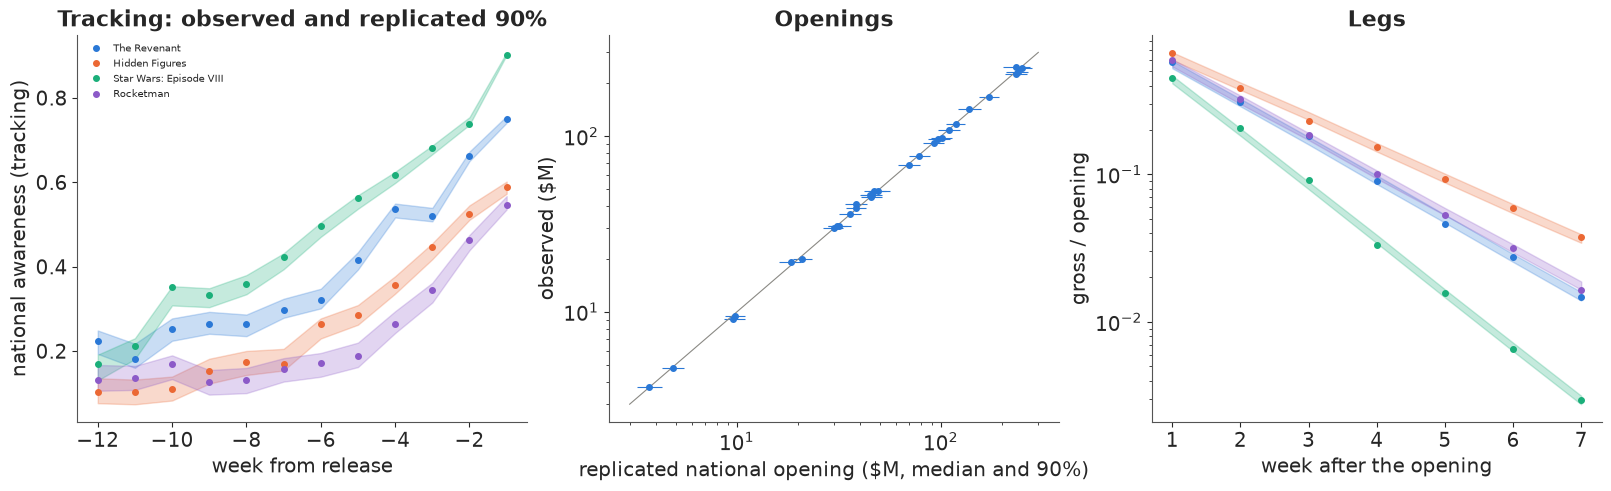

In [14]:
with m_test:
    ppc = pm.sample_posterior_predictive(idata_T.isel(draw=slice(None, None, 10)), var_names=["track", "opening", "legs"],
                                         random_seed=RANDOM_SEED, progressbar=False)
rep = {k: ppc.posterior_predictive[k].to_numpy().reshape((-1,) + ppc.posterior_predictive[k].shape[2:])
       for k in ["track", "opening", "legs"]}
del ppc
obsv = {"track": D_TEST["z"], "opening": D_TEST["yO"], "legs": D_TEST["rG"]}
for k in rep:
    lo, hi = np.quantile(rep[k], [0.05, 0.95], axis=0)
    print(f"{k}: {np.mean((obsv[k] >= lo) & (obsv[k] <= hi)):.0%} of {obsv[k].size:,} observed values inside their 90% "
          "predictive interval")
natT_rep = ((1 - np.exp(rep["track"])) * P_M[None, None, :, None]).sum(2)
natT_obs = ((1 - np.exp(D_TEST["z"])) * P_M[None, :, None]).sum(1)
O_rep = (np.exp(rep["opening"]) * P_M[None, None, :]).sum(2)
O_obs = (np.exp(D_TEST["yO"]) * P_M[None, :]).sum(1)
lo, hi = np.quantile(O_rep, [0.05, 0.95], axis=0)
print(f"national opening inside its 90% interval: {np.mean((O_obs >= lo) & (O_obs <= hi)):.0%} of {NF} films")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
ax = axes[0]
for k_, j in enumerate([0, 7, 15, 25]):
    col = [BLUE, ORANGE, AQUA, PURPLE][k_]
    ax.fill_between(KW[:12], *np.quantile(natT_rep[:, j], [0.05, 0.95], axis=0), color=col, alpha=0.25)
    ax.plot(KW[:12], natT_obs[j], "o", color=col, ms=4, label=f.label.iloc[SUB[j]][:24])
ax.set(xlabel="week from release", ylabel="national awareness (tracking)", title="Tracking: observed and replicated 90%")
ax.legend(fontsize=7)
ax = axes[1]
med = np.median(O_rep, 0)
ax.errorbar(med, O_obs, xerr=np.abs(np.quantile(O_rep, [0.05, 0.95], axis=0) - med), fmt="o", color=BLUE, ms=4, lw=0.8)
lim = [min(O_obs.min(), med.min()) * 0.8, max(O_obs.max(), med.max()) * 1.2]
ax.plot(lim, lim, color=MUTED, lw=0.8)
ax.set(xscale="log", yscale="log", xlabel="replicated national opening ($M, median and 90%)", ylabel="observed ($M)",
       title="Openings")
ax = axes[2]
lg_obs = (np.exp(D_TEST["rG"]) * np.exp(D_TEST["yO"])[:, :, None] * P_M[None, :, None]).sum(1) / O_obs[:, None]
lg_rep = (np.exp(rep["legs"]) * np.exp(rep["opening"])[..., None] * P_M[None, None, :, None]).sum(2) / O_rep[..., None]
for k_, j in enumerate([0, 7, 15, 25]):
    col = [BLUE, ORANGE, AQUA, PURPLE][k_]
    ax.fill_between(np.arange(1, 8), *np.quantile(lg_rep[:, j], [0.05, 0.95], axis=0), color=col, alpha=0.25)
    ax.plot(np.arange(1, 8), lg_obs[j], "o", color=col, ms=4)
ax.set(yscale="log", xlabel="week after the opening", ylabel="gross / opening", title="Legs");

The checks are good, as they should be when the model's form is nearly the simulator's (it leaves
out the local buzz). Of the observed values, 94% of tracking cells, 95% of market openings and 91%
of later weeks fall inside their 90% intervals, as do all 30 national openings. The replicated
national tracking follows each film's build-up (left), the openings scatter along the diagonal
(middle), and the legs (right) decay at each film's own rate. These checks cannot tell whether the
model would predict a schedule the studios never ran. That is the next question.

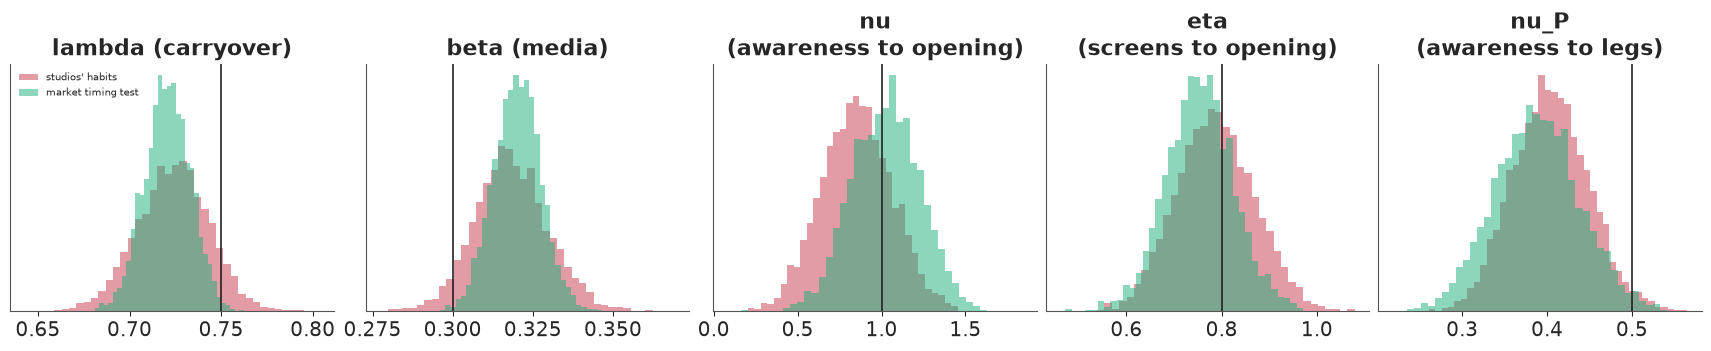

In [15]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.4))
for ax, (v, tv) in zip(axes, [("lam", 0.75), ("beta", 0.30), ("nu", 1.0), ("eta", 0.8), ("nuP", 0.5)]):
    for name, col in [("studios' habits", RED), ("market timing test", AQUA)]:
        ax.hist(POST[(name, v)], bins=40, density=True, alpha=0.5, color=col, label=name)
    ax.axvline(tv, color=INK, lw=1.2)
    ax.set(title={"lam": "lambda (carryover)", "beta": "beta (media)", "nu": "nu\n(awareness to opening)",
                  "eta": "eta\n(screens to opening)", "nuP": "nu_P\n(awareness to legs)"}[v], yticks=[])
axes[0].legend(fontsize=7);

## E · What the experiment buys

In the world so far, media works the same way in every market. Suppose instead that it works
better where interest is already high - a trailer lands better with people inclined to the genre:
$\beta_{fm} = \beta\, e^{1.5 \mu_{fm}}$, about $\pm 30\%$ between markets. Suppose also that
studios have no natural noise in their market budgets, that the late tilt toward weak markets is
stronger, and that local buzz is stronger (its weekly innovations sd 0.2 instead of 0.08). Our
model does not know any of this. We ask the crude within-market estimator of part C, in five such
worlds with and without the test. Then we refit the PyMC model to the test films twice: once with
the stronger tilt and buzz alone, and once with media varying by market as well, so that the two
changes can be told apart.

In [16]:
TRUE_HET = dict(TRUE, het=1.5)
rows = []
for world, th, kw, ar in [("base", TRUE, dict(), 0.08), ("strong tilt, no natural noise", TRUE, dict(tilt_k=4.0, nat_sd=0.0), 0.2),
                          ("... and media varies by market", TRUE_HET, dict(tilt_k=4.0, nat_sd=0.0), 0.2)]:
    for r in range(5):
        nz = make_noise(F, 100 + r, ar_sd=ar)
        o = observational(fp, nz, th=th, seed=200 + r, **kw)
        oT = observational(fp, nz, th=th, test_frac=0.4, seed=200 + r, **kw)
        for lab, (lam_, b_) in [("studios' habits", within_market(o)),
                                ("market timing test", within_market(oT, np.flatnonzero(oT["in_test"])))]:
            rows.append(dict(world=world, data=lab, rep=r, lam=lam_, beta=b_))
HETW = pd.DataFrame(rows)
print("within-film market x week estimator, mean (min-max) over 5 worlds; truth lambda 0.75, beta 0.30")
print(HETW.groupby(["world", "data"], sort=False)[["lam", "beta"]].agg(["mean", "min", "max"]).round(2).to_string())

nz_h = make_noise(F, 101, ar_sd=0.2)
FIT_H = []
for lab, th in [("strong tilt, no natural noise", TRUE), ("... and media varies by market", TRUE_HET)]:
    obT_h = observational(fp, nz_h, th=th, test_frac=0.4, seed=201, tilt_k=4.0, nat_sd=0.0)
    t0 = time.time()
    with build(prep(obT_h, SUB)):
        idata_h = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
    FIT_H.append(report(lab, idata_h, time.time() - t0))
    del idata_h
print("joint model on the 30 test films of each world (local buzz sd 0.2 in both); truth in brackets, 89% intervals")
print(pd.DataFrame(FIT_H).set_index("fit").T.to_string())

within-film market x week estimator, mean (min-max) over 5 worlds; truth lambda 0.75, beta 0.30
                                                    lam              beta            
                                                   mean   min   max  mean   min   max
world                          data                                                  
base                           studios' habits     0.43  0.40  0.50  0.18  0.17  0.19
                               market timing test  0.74  0.70  0.75  0.30  0.28  0.31
strong tilt, no natural noise  studios' habits     0.82  0.80  0.85  0.21  0.20  0.21
                               market timing test  0.74  0.70  0.75  0.30  0.27  0.32
... and media varies by market studios' habits     0.95  0.95  0.95  0.08  0.07  0.08
                               market timing test  0.72  0.70  0.75  0.31  0.30  0.34


joint model on the 30 test films of each world (local buzz sd 0.2 in both); truth in brackets, 89% intervals
fit                  strong tilt, no natural noise ... and media varies by market
seconds                                         50                             65
divergences                                      0                              0
max r_hat                                    1.005                          1.007
min ESS (bulk, tail)                          1006                            825
max depth                                        7                              8
lam (0.75)                       0.69 [0.66, 0.72]              0.52 [0.46, 0.58]
beta (0.3)                       0.34 [0.32, 0.36]              0.26 [0.24, 0.28]
nu (1.0)                         1.01 [0.70, 1.32]              1.07 [0.85, 1.29]
eta (0.8)                        0.76 [0.65, 0.87]              0.77 [0.66, 0.88]
nuP (0.5)                        0.26 [0.18, 0.33]              0.09 [0

The crude estimator on the test films stays within a grid step of the truth in every world:
$\lambda$ 0.74 on average in the base world, 0.74 with a strong tilt and no natural noise, and
0.72 when media varies by market, with $\beta$ near 0.30 throughout. On the studios' habits it is
off in every world, in different directions: $\lambda$ 0.43 in the base world, 0.82 with a strong
tilt, and 0.95 (the edge of the grid) with $\beta$ = 0.08 when media varies by market.
Randomisation makes the markets comparable, so the estimator needs no model of how media and
organic interest combine across markets; it still takes the weekly response curve as known.

**Failure 5: the joint model, fitted to the same test films, drifts as its form moves away from
the simulator's.** Both samplers are as healthy as before - no divergences, r_hat at most about
1.01 - and both posteriors are confidently off. Stronger local buzz, which the model has no term
for, together with the loss of natural noise in market budgets, already moves $\lambda$ to 0.69
(89% interval 0.66-0.72) and $\nu_P$ to 0.26, the attenuation of part D made larger. (The tilt
does not reach test films; the natural noise did, through each test market's total.) Media that
varies by market on top makes it much worse:
$\lambda$ = 0.52 (0.46-0.58), $\beta$ = 0.26 and $\nu_P$ = 0.09 against 0.5. The model has one
$\beta$ for all markets; the test's long and short campaigns land in markets that respond
differently, and it absorbs the mismatch in how fast awareness decays. The experiment gave the
data the right variation, and the model still read it through a wrong form. Each fit is one
world, so it shows the direction of a mismatch more than its size.

Put together with part D: with nearly the right form, the observational data identified the timing
and the experiment added little; as the form drifted, the experiment kept the simple within-market
estimate right and the joint model wrong. **The experiment buys robustness to the model.** Its
best use is to grade and correct the model, as E103 used a few holdouts to calibrate many
observational estimates; the third exercise does this.

## F · When should the money go?

Now the decision. For each of the 30 films the studio keeps its budget, the film's observed total,
and chooses how to split it over the sixteen weeks from -12 to +3. That total includes the money
the studio added after a good opening (5-22% of the budget across these films), a decision made
after the release that we treat as movable. A schedule is a softmax of 16 free weights times the
budget, and we maximise **expected studio returns** with L-BFGS from two starts (the studio's
schedule and an even one). The model's expected returns come from forward simulation: for each of
100 posterior draws of the test fit, push the schedule through the stock, awareness, the
exhibitors' rule, the opening and the legs, and average the returns over draws. The Student-t
opening has no finite mean on the gross scale, so the forward model uses the median scale; at a
fixed budget a common factor does not move the optimum.

Every schedule is then scored in the **true** simulator for the film as it turned out: its
realised size surprise, market interest, local buzz and the exhibitors' own judgement, with only
the survey error and the noise of the later weeks averaged out. The model knows the same film, as
its posterior learnt the organic path, market effects and film effect from the finished release.
This is an after-the-fact comparison, as in E104, and it flatters the model-based schedules, which
use what a studio would not know before release. We score the studio's schedule (its national
weekly totals, split across markets by population, so without its market tilt), the posterior
optimum, the posterior-mean plug-in optimum, the true optimum (an oracle that knows the simulator
and the realised film), and the naive model's advice. The naive cross-film model of part C says
the best money is the earliest (\$13.9 of opening per dollar in weeks -12 to -7 in this world,
\$5.8 in weeks -6 to -3, a loss in the last three weeks). Its schedule splits the budget in
proportion to those opening figures, leaving out the negative one: about 70% in weeks -12 to -7,
30% in weeks -6 to -3, and nothing later.

In [17]:
po = az.extract(idata_T, var_names=["lam", "beta", "nu", "eta", "nuP", "z0", "z1", "z2", "c", "delta", "l0", "zrw",
                                    "sd_rw", "mu", "sd_mu"], num_samples=400, random_seed=1)
POSTD = {k: po[k].to_numpy() for k in po.data_vars}
del po, idata_T


def sub(i):
    return {k: (v[i:i + 1] if isinstance(v, np.ndarray) and v.shape[:1] == (F,) else v) for k, v in fp.items()}


def realised(i, nz=nz_dec):
    """Film i as it turned out in the decision world: its size surprise, market interest, local buzz and the
    exhibitors' judgement; survey error and later weeks' noise are averaged out."""
    return dict(u=nz["u"][i:i + 1], eps=nz["eps"][i:i + 1], mk=nz["mk"][i:i + 1], ar=nz["ar"][i:i + 1],
                zs=nz["zs"][i:i + 1], surv=None, g=None)


def true_returns(i, s_k, th=TRUE, film=None, what="returns"):
    """True studio returns (or total gross) of film i under a national weekly schedule: the expected film
    (film=None) or a realised one (film=realised(i))."""
    fi = sub(i)
    s = s_k[None, None, :] * P_M[None, :, None]
    G, *_ = gross_paths(fi, s, th, fi["clutter"], noise=film)
    return float(returns(G, fi, s.sum(1))[0 if what == "returns" else 1][0])


def screen_share(i, s_k, film=None):
    fi = sub(i)
    _, scr, *_ = gross_paths(fi, s_k[None, None, :] * P_M[None, :, None], TRUE, fi["clutter"], noise=film)
    return float((scr[0] * P_M).sum())


class ModelFilm:
    """Expected studio returns of one fitted film under a national weekly schedule, for a set of posterior draws."""

    def __init__(self, post, j, i, draws):
        g = lambda k: post[k][..., draws]
        self.lam, self.beta, self.nu, self.eta, self.nuP = (g(k) for k in ["lam", "beta", "nu", "eta", "nuP"])
        self.z0, self.z1, self.z2 = g("z0"), g("z1"), g("z2")
        self.c, self.delta = g("c")[j], g("delta")[j]
        ell = np.concatenate([g("l0")[j][None], g("l0")[j][None] + np.cumsum(g("sd_rw") * g("zrw")[j], 0)], 0)
        self.ellf = np.concatenate([ell, np.repeat(ell[-1:], NK - 12, 0)], 0)          # (week, draw)
        self.mu = g("mu")[j] * g("sd_mu")[None]                                         # (market, draw)
        self.clut, self.lsize = fp["clutter"][i], fp["lsize"][i]

    def returns(self, s_k):
        x = np.log1p(s_k[None, :] / (TRUE["kappa"] * (1 + TRUE["chi"] * self.clut[None, :])))   # same in every market
        M, Ms = np.zeros((NM, self.lam.shape[0])), []
        for k in range(NK):
            M = self.lam[None] * M + x[:, k:k + 1]
            Ms.append(M)
        M = np.stack(Ms, 1)                                                              # (market, week, draw)
        law = np.log1p(-np.exp(-(np.exp(self.ellf[None] + self.mu[:, None, :]) + self.beta * M)))
        scr = expit(self.z0 + self.z1 * logit(np.exp(law[:, JD, :])).mean(1) + self.z2 * self.lsize)
        O = P_M[:, None] * np.exp(self.c[None] + self.nu * law[:, J0, :] + self.eta * np.log(scr))
        Mp = np.concatenate([M[:, J0 + 1:, :], M[:, -1:, :] * self.lam[None, None] ** np.arange(1, 5)[None, :, None]], 1)
        lawp = np.log1p(-np.exp(-(np.exp(self.ellf[None, -1:, :] + self.mu[:, None, :]) + self.beta * Mp)))
        G = np.concatenate([O[:, None, :], O[:, None, :] * np.exp(-self.delta * np.arange(1, 8)[None, :, None]
                                                                   + self.nuP * (lawp - law[:, J0:J0 + 1, :]))], 1).sum(0)
        r = np.exp(-self.delta)
        return (G * SHARE[:, None]).sum(0) + SHARE_TAIL * G[-1] * r / (1 - r) - s_k.sum()


def optimise(obj, budget, z0):
    best = None
    for start in [z0, np.zeros(NK)]:
        res = minimize(lambda z: -obj(budget * softmax(z)), start, method="L-BFGS-B", options=dict(maxiter=300))
        if best is None or res.fun < best.fun:
            best = res
    return budget * softmax(best.x)


def naive_schedule(o, budget):
    O = o["G"][:, :, 0].sum(1)
    sb = [o["s"][:, :, BUCKETS[b]].sum((1, 2)) for b in PRE_B]
    b_ = np.linalg.lstsq(np.column_stack([np.ones(F)] + [np.log(v + 0.1) for v in sb]), np.log(O), rcond=None)[0]
    marg = np.array([np.mean(b_[1 + k] * O / (sb[k] + 0.1)) for k in range(3)])
    w = np.zeros(NK)
    for k, b in enumerate(PRE_B):
        w[BUCKETS[b]] = max(marg[k], 0) / BUCKETS[b].sum()
    return budget * w / w.sum(), marg


t0 = time.time()
ndraw = POSTD["lam"].shape[-1]
dsel = np.random.default_rng(3).choice(ndraw, 100, replace=False)
pmean = {k: v.mean(-1, keepdims=True) for k, v in POSTD.items()}
pmean["mu"] = (POSTD["mu"] * POSTD["sd_mu"]).mean(-1, keepdims=True)         # means of the products
pmean["zrw"] = (POSTD["zrw"] * POSTD["sd_rw"]).mean(-1, keepdims=True)
pmean["sd_mu"], pmean["sd_rw"] = np.ones(1), np.ones(1)
rows, SCHED, GP = [], {}, []
for j, i in enumerate(SUB):
    budget, std = float(ob["s"][i].sum()), ob["s"][i].sum(0)
    mf, mp = ModelFilm(POSTD, j, i, dsel), ModelFilm(pmean, j, i, np.array([0]))
    z0 = np.log(std / budget + 1e-4)
    fr = realised(i)
    S = dict(standard=std, true=optimise(lambda s: true_returns(i, s, film=fr), budget, z0),
             posterior=optimise(lambda s: mf.returns(s).mean(), budget, z0),
             plugin=optimise(lambda s: mp.returns(s)[0], budget, z0), naive=naive_schedule(ob, budget)[0],
             gross=optimise(lambda s: true_returns(i, s, film=fr, what="gross"), budget, z0))
    SCHED[i] = S
    row = dict(film=i, label=f.label.iloc[i], budget=budget, series=bool(fp["series"][i]), fc=fp["fc"][i],
               delta=fp["delta"][i], clutter=float(fp["clutter"][i, J0 - 2:J0 + 1].mean()),
               scr_std=screen_share(i, std, fr), scr_true=screen_share(i, S["true"], fr))
    row.update({f"R_{k}": true_returns(i, s, film=fr) for k, s in S.items()})
    row.update({f"G_{k}": true_returns(i, S[k], film=fr, what="gross") for k in ["standard", "true", "gross"]})
    gp = mf.returns(S["posterior"]) - mf.returns(std)                        # same 100 draws for every film
    GP.append(gp)
    row.update(pred_gain=gp.mean(), pred_lo=np.quantile(gp, 0.05), pred_hi=np.quantile(gp, 0.95))
    rows.append(row)
DEC = pd.DataFrame(rows)
marg_naive = naive_schedule(ob, 1.0)[1]
print(f"{NF} films optimised in {time.time() - t0:.0f} s; naive model's opening $ per $1 by bucket: "
      + ", ".join(f"{b} {v:.1f}" for b, v in zip(PRE_B, marg_naive)))
psh = np.array([ob["s"][i][:, KW >= 1].sum() / ob["s"][i].sum() for i in SUB])
print(f"post-release share of the studio's budget, min / median / max over the {NF} films: "
      f"{psh.min():.0%} / {np.median(psh):.0%} / {psh.max():.0%}")
tot = {k: DEC[f"R_{k}"].sum() for k in ["standard", "true", "posterior", "plugin", "naive"]}
print(f"true expected studio returns over the {NF} films, standard schedules: ${tot['standard']:,.0f}M (budgets "
      f"${DEC.budget.sum():,.0f}M)")
for k, lab in [("true", "true optimum (oracle)"), ("posterior", "posterior draws, test fit"),
               ("plugin", "posterior-mean plug-in"), ("naive", "naive cross-film advice")]:
    g_ = DEC[f"R_{k}"] - DEC.R_standard
    print(f"  {lab:28s} gain ${g_.sum():+,.0f}M ({g_.sum() / tot['standard']:+.0%}); worse than standard for "
          f"{(g_ < -1e-6).sum()} of {NF} films")
DEC["gain"] = DEC.R_posterior - DEC.R_standard
cov = ((DEC.gain >= DEC.pred_lo) & (DEC.gain <= DEC.pred_hi)).mean()
gp_tot = np.sum(GP, axis=0)
print(f"model-predicted total gain ${gp_tot.mean():,.0f}M, 90% interval ${np.quantile(gp_tot, 0.05):,.0f}M to "
      f"${np.quantile(gp_tot, 0.95):,.0f}M (true ${DEC.gain.sum():,.0f}M); per-film 90% intervals cover the true gain "
      f"for {cov:.0%} of films; posterior beats plug-in by more than $0.1M for "
      f"{(DEC.R_posterior > DEC.R_plugin + 0.1).sum()} films")
g_exp = np.array([true_returns(i, SCHED[i]["posterior"]) - true_returns(i, SCHED[i]["standard"]) for i in SUB])
print(f"the same intervals against the gain for the expected film (all realised shocks at zero): cover "
      f"{((g_exp >= DEC.pred_lo) & (g_exp <= DEC.pred_hi)).mean():.0%} of films")
w_n = np.mean([SCHED[i]["naive"][BUCKETS[PRE_B[0]]].sum() / SCHED[i]["naive"].sum() for i in SUB])
print(f"naive advice: {w_n:.0%} of the budget in weeks -12..-7, {1 - w_n:.0%} in weeks -6..-3")
wk0 = {k: np.mean([SCHED[i][k][J0] / SCHED[i][k].sum() for i in SUB]) for k in ["true", "gross"]}
lt = {k: np.mean([SCHED[i][k][BUCKETS["late (-2..0)"]].sum() / SCHED[i][k].sum() for i in SUB]) for k in ["true", "gross"]}
md_ = np.mean([SCHED[i]["true"][BUCKETS["mid (-6..-3)"]].sum() / SCHED[i]["true"].sum() for i in SUB])
print(f"true optimum, mean over the {NF} films: weeks -6..-3 {md_:.0%}, weeks -2..0 {lt['true']:.0%}, "
      f"opening week {wk0['true']:.0%}")
print(f"maximising total gross instead of returns: gross ${DEC.G_gross.sum() - DEC.G_true.sum():+,.1f}M over the "
      f"returns optimum, returns ${DEC.R_gross.sum() - DEC.R_true.sum():+,.1f}M; opening-week share {wk0['true']:.0%} -> "
      f"{wk0['gross']:.0%}, weeks -2..0 {lt['true']:.0%} -> {lt['gross']:.0%}")

30 films optimised in 64 s; naive model's opening $ per $1 by bucket: early (-12..-7) 13.9, mid (-6..-3) 5.8, late (-2..0) -1.1
post-release share of the studio's budget, min / median / max over the 30 films: 5% / 14% / 22%
true expected studio returns over the 30 films, standard schedules: $1,234M (budgets $1,511M)
  true optimum (oracle)        gain $+179M (+14%); worse than standard for 0 of 30 films
  posterior draws, test fit    gain $+176M (+14%); worse than standard for 0 of 30 films
  posterior-mean plug-in       gain $+175M (+14%); worse than standard for 0 of 30 films
  naive cross-film advice      gain $-539M (-44%); worse than standard for 30 of 30 films
model-predicted total gain $169M, 90% interval $138M to $194M (true $176M); per-film 90% intervals cover the true gain for 100% of films; posterior beats plug-in by more than $0.1M for 1 films
the same intervals against the gain for the expected film (all realised shocks at zero): cover 63% of films
naive advice: 71% of the

Over the 30 films the studios' schedules earn \$1,234M of returns on \$1,511M of P&A. Moving the
same money to the right weeks earns **\$179M more (+14%)** for an oracle that knows the simulator,
and the posterior schedules capture \$176M of it; no film does worse than under the studio's
schedule. The naive model's advice, mostly seven to twelve weeks out and the rest in
weeks -6 to -3, would lose \$539M, 44% of the studios' returns, and is worse than the studio's
schedule for all 30 films.

The model's own forecast of the gain is close: \$169M, with a 90% interval of \$138M to \$194M
for the total, against the true \$176M. Its per-film 90% intervals cover the true gain for all 30
films (figure below), but those are not 30 independent checks: every film's interval rests on the
same $\lambda$, $\beta$, $\nu$ and $\eta$, so they move together, and the total is the fairer
test. Scored against the expected film instead, with every realised shock set to zero, the same
intervals cover only 63% of films, because the model's film effects describe the film as it turned
out. Optimising the average over 100 draws rather than the posterior mean barely matters here
(\$176M against \$175M; only one film gains more than \$0.1M from optimising over draws), because
this posterior is tight.

What if the studio's target were the box office itself? At a fixed budget the two objectives
differ only in the rental share, so maximising the gross could move money. Here it does not: the
gross-maximising schedules put the same 17% in the opening week and 39% in weeks -2 to 0, and gain
\$0.3M of gross for \$0.1M of returns. With the budget fixed, the weeks that raise the opening
raise both.

### F1 · The schedule by type of film

Which weeks get the money? We sort the 30 films into types, using thresholds from all 206: a
**franchise tentpole** (part of a series, top third of expected gross), a **slow-legs** film
(bottom quarter of the gross decay rate), a film opening in a **crowded** week (top
quarter of rivals' clutter around release), an **original mid-budget** film (not in a series,
expected gross between the 20th and 66th percentiles), and the rest, in that order.

In [18]:
qfc = (np.argsort(np.argsort(fp["fc"])) + 0.5) / F
TYPE_ALL = np.select([fp["series"] & (qfc > 0.66), fp["delta"] < np.quantile(fp["delta"], 0.25),
                      fp["clutter"][:, J0 - 2:J0 + 1].mean(1) > np.quantile(fp["clutter"][:, J0 - 2:J0 + 1].mean(1), 0.75),
                      ~fp["series"] & (qfc > 0.2) & (qfc <= 0.66)],
                     ["franchise tentpole", "slow legs", "crowded release week", "original mid-budget"],
                     "other")
DEC["type"] = TYPE_ALL[SUB]
TYPES = ["franchise tentpole", "original mid-budget", "slow legs", "crowded release week", "other"]
for k in ["standard", "true", "posterior"]:
    W_ = np.stack([SCHED[i][k] / SCHED[i][k].sum() for i in SUB])
    for b, m in BUCKETS.items():
        DEC[f"{k}: {b.split()[0]}"] = W_[:, m].sum(1)
agg = DEC.groupby("type").agg(films=("film", "size"), budget=("budget", "median"), R_std=("R_standard", "sum"),
                              gain_true=("R_true", "sum"), gain_post=("R_posterior", "sum"),
                              screens_std=("scr_std", "mean"), screens_opt=("scr_true", "mean"))
agg["gain_true"] -= agg.R_std
agg["gain_post"] -= agg.R_std
agg["gain %"] = 100 * agg.gain_true / agg.R_std
for k in ["standard", "true", "posterior"]:
    for b in ["early", "mid", "late", "post"]:
        agg[f"{k[:4]} {b}"] = DEC.groupby("type")[f"{k}: {b}"].mean()
DEC["true: week 0"] = [SCHED[i]["true"][J0] / SCHED[i]["true"].sum() for i in SUB]
agg["true wk 0"] = DEC.groupby("type")["true: week 0"].mean()
agg = agg.reindex(TYPES)
c1 = ["films", "budget", "R_std", "gain_true", "gain_post", "gain %", "screens_std", "screens_opt"]
print("gains ($M) and the national screen share under the standard schedule and the true optimum, by type:")
print(agg[c1].round(2).to_string())
print("budget shares by bucket: standard schedule, true optimum, posterior optimum")
print(agg.drop(columns=c1).round(2).to_string())

gains ($M) and the national screen share under the standard schedule and the true optimum, by type:
                      films  budget   R_std  gain_true  gain_post  gain %  screens_std  screens_opt
type                                                                                               
franchise tentpole        6   81.26  509.28      27.75      27.07    5.45         0.91         0.95
original mid-budget       2   31.09   27.24       9.91       9.79   36.37         0.69         0.80
slow legs                 8   38.30  181.41      82.35      81.21   45.40         0.56         0.70
crowded release week      4   16.63    4.36      15.83      15.64  363.21         0.35         0.47
other                    10   58.10  511.56      42.95      41.99    8.40         0.70         0.76
budget shares by bucket: standard schedule, true optimum, posterior optimum
                      stan early  stan mid  stan late  stan post  true early  true mid  true late  true post  post early  po

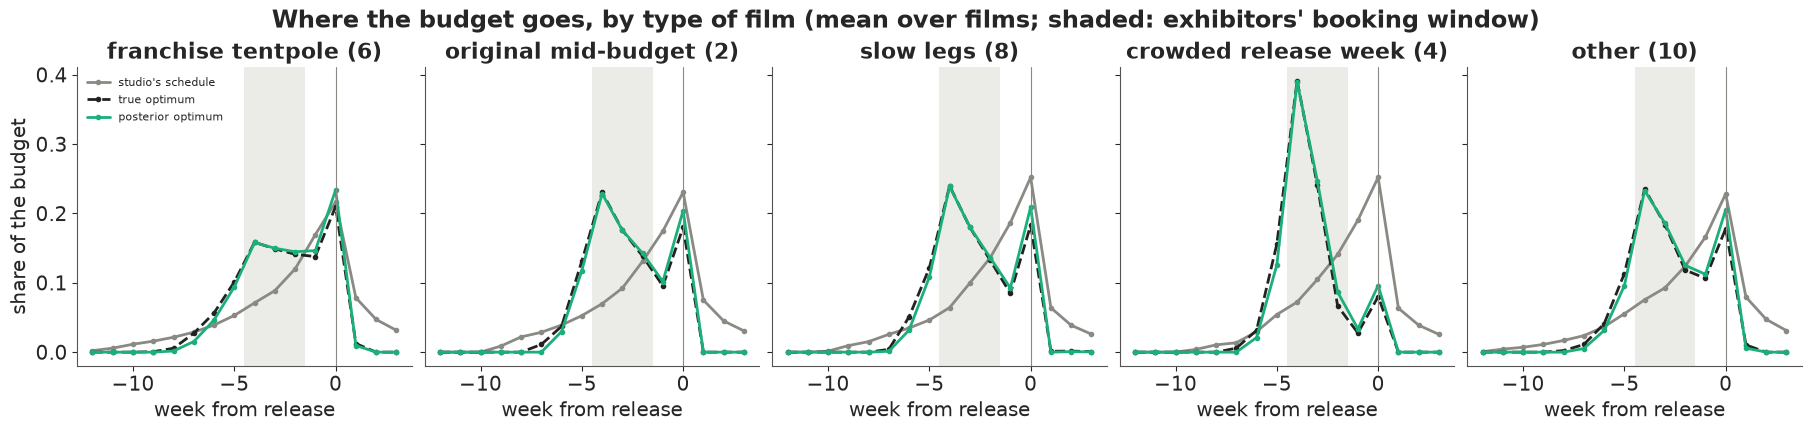

In [19]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4.2), sharey=True)
for ax, t_ in zip(axes, TYPES):
    ids = SUB[DEC.type.to_numpy() == t_]
    for k, col, ls in [("standard", MUTED, "-"), ("true", INK, "--"), ("posterior", AQUA, "-")]:
        W_ = np.stack([SCHED[i][k] / SCHED[i][k].sum() for i in ids]).mean(0)
        ax.plot(KW, W_, ls, color=col, lw=2, marker="o", ms=3, label={"standard": "studio's schedule",
                                                                      "true": "true optimum",
                                                                      "posterior": "posterior optimum"}[k])
    ax.axvspan(-4.5, -1.5, color=LIGHT, alpha=0.5, lw=0)
    ax.axvline(0, color=MUTED, lw=0.8)
    ax.set(title=f"{t_} ({len(ids)})", xlabel="week from release")
axes[0].set_ylabel("share of the budget")
axes[0].legend(fontsize=8)
fig.suptitle("Where the budget goes, by type of film (mean over films; shaded: exhibitors' booking window)");

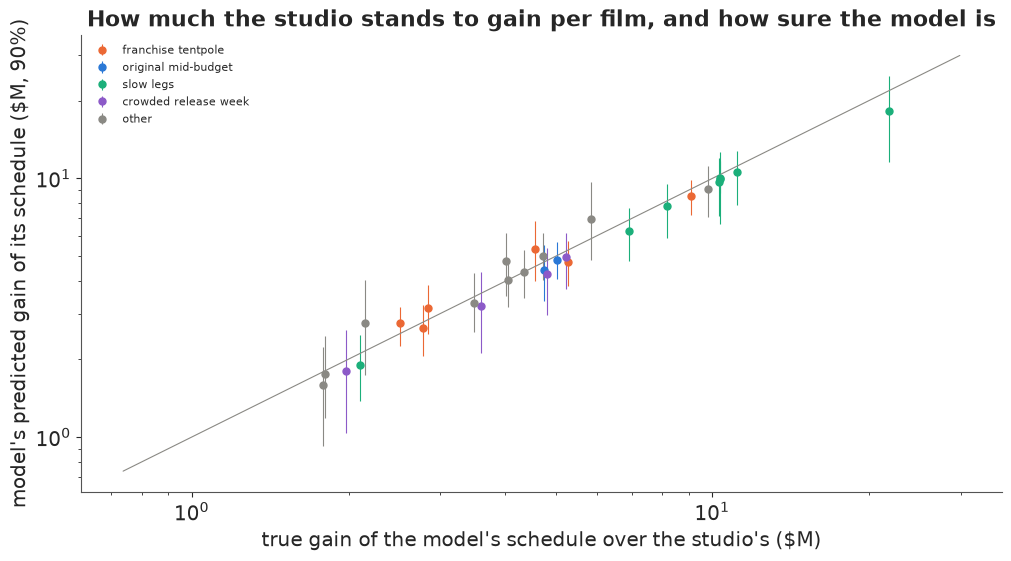

In [20]:
fig, ax = plt.subplots(figsize=(10, 5.5))
g_true, g_post, g_naive = (DEC[f"R_{k}"] - DEC.R_standard for k in ["true", "posterior", "naive"])
for t_, col in zip(TYPES, [ORANGE, BLUE, AQUA, PURPLE, MUTED]):
    m_ = DEC.type == t_
    ax.errorbar(g_post[m_], DEC.pred_gain[m_], yerr=np.vstack([DEC.pred_gain[m_] - DEC.pred_lo[m_],
                                                              DEC.pred_hi[m_] - DEC.pred_gain[m_]]),
                fmt="o", color=col, ms=5, lw=0.8, label=t_)
lim = [min(g_post.min(), DEC.pred_lo.min()) * 0.8, max(g_post.max(), DEC.pred_hi.max()) * 1.2]
ax.plot(lim, lim, color=MUTED, lw=0.8)
ax.set(xscale="log", yscale="log", xlabel="true gain of the model's schedule over the studio's ($M)",
       ylabel="model's predicted gain of its schedule ($M, 90%)",
       title="How much the studio stands to gain per film, and how sure the model is")
ax.legend(fontsize=8);

The answer has a common shape and differs by type. For every type almost nothing goes earlier than
week -7 or after the release: the optimum puts the money in **one burst over weeks -6 to 0**. For
most types it peaks at week -4, as the tracking that exhibitors book from begins, dips at week -1
(after the booking window, and not yet the opening), and peaks again in the opening week, where
the studio's rental share is highest: about a fifth of the budget goes into week 0. The studios'
schedules spend too early - bigger films start up to twelve weeks out - and keep 13-16% of the
budget for after the release, where it buys almost nothing.

The split between mid-campaign (-6 to -3, ending inside the booking window) and the last three
weeks (-2 to 0) differs by type. **Franchise tentpoles** (6 films) are the exception to the shape:
they split evenly, 47% and 49%, flat from week -4 to -1 with a single peak at week 0. Their
screens are already near the top of what exhibitors give - a national screen share of 0.91 under
the studio's schedule, against 0.35-0.70 for the other types - so money that buys screens is
worth less. They gain the least in proportion, \$28M or 5%, because their gross is large and
their campaign was closest to right. The ten **other** films, mostly large releases outside a
series as Wikidata records it, sit between them and the rest: 57% mid-campaign, a gain of \$43M or
8%.

The smaller films lean toward mid-campaign. **Original mid-budget** films (only 2 in this sample
of 30) and **slow-legs** films (8) put 57-59% there and gain 36-45%: they need awareness by the
time exhibitors read the tracking, and the optimum lifts their screen share from 0.56-0.69 to
0.70-0.80. Slow legs raise the value of a good opening but do not change when to buy it. Films
opening in a **crowded week** (4) are the extreme: 82% mid-campaign, a peak of nearly 40% of the
budget at week -4, and only 8% in the opening week, where rivals' campaigns make every dollar
dearer. Their schedules earned only \$4M of returns between them, so their gain of \$16M is the
largest in proportion. The optimum spends next to nothing after release, for every type, because
in this world viewers do not create awareness; the first exercise adds word of mouth that does
(Liu 2006).

The posterior optimum is within about 0.05 of the true one in every share, for every type.

### F2 · One burst or pulses?

Classic advertising theory asks whether to spend evenly or in pulses. With a concave weekly
response, spreading is cheaper per unit of stock; with an S-shaped one, concentration can win
(Mahajan & Muller 1986). Here returns depend on awareness at two moments, the booking window and
the opening. We re-optimise one film (the median budget among the 206) with the true model under
the concave response and under an S-shaped one, $2x^3 / (1 + x^3)$, from six starting points, and
compare with an even spread over weeks -12 to 0.

In [21]:
i_med = int(np.argsort(fp["fc"])[F // 2])
B_med = float(fp["budget"][i_med])
even = np.where(KW <= 0, B_med / 13, 0.0)                                    # the whole budget, evenly over weeks -12..0
rs_p = np.random.default_rng(0)
pulse = []
for lab, th in [("concave log(1 + x)", TRUE), ("S-shaped 2x^3/(1 + x^3)", dict(TRUE, resp="s"))]:
    best = None
    for k in range(6):
        z0 = rs_p.normal(0, 1, NK) if k else np.log(ramp(int(fp["L"][i_med])) + 1e-3)
        res = minimize(lambda z: -true_returns(i_med, B_med * softmax(z), th), z0, method="L-BFGS-B")
        if best is None or res.fun < best.fun:
            best = res
    s_opt = B_med * softmax(best.x)
    pulse.append(dict(response=lab, best=-best.fun, even=true_returns(i_med, even, th),
                      standard=true_returns(i_med, B_med * ramp(int(fp["L"][i_med])), th),
                      weeks_above_5pct=int((s_opt / B_med > 0.05).sum()),
                      schedule=" ".join(f"{v:.0f}" for v in 100 * s_opt / B_med)))
print(f"{f.label.iloc[i_med]}: budget ${B_med:.0f}M; expected studio returns ($M) and the best schedule "
      "(% of budget, weeks -12..+3)")
print(pd.DataFrame(pulse).round(1).to_string(index=False))

Sully: budget $31M; expected studio returns ($M) and the best schedule (% of budget, weeks -12..+3)
               response  best  even  standard  weeks_above_5pct                              schedule
     concave log(1 + x)  28.5  19.0      22.8                 6 0 0 0 0 0 0 2 11 23 19 15 11 20 0 0 0
S-shaped 2x^3/(1 + x^3)  43.4   3.5      19.3                 5  0 0 0 0 0 0 0 0 23 21 19 17 20 0 0 0


No pulsing appears for this film. Under both responses the best schedule we found for Sully is one
contiguous burst: weeks -5 to 0 under the concave response (six weeks above 5% of the budget) and
weeks -4 to 0 under the S-shaped one (five). The shape sets how wide the burst is, and how much
spreading costs: the whole budget spread evenly over weeks -12 to 0 earns \$19.0M against \$28.5M
at the optimum under the concave response, and only \$3.5M against a \$43.4M optimum under the
S-shaped one, because no week's spend reaches the steep part of the curve. (The two responses are
different worlds, so their returns are not comparable with each other.) This is one film and a
local optimiser on a non-convex problem, so it shows that pulsing need not pay rather than that it
never does. Pulsing pays when the goal is awareness sustained over a long period; a release is a
single date.

## Where this leaves the studio

The simulator is ours, so the numbers are ours; what transfers is the reasoning. In this world the
answer to "when?" is: about three fifths of the budget in weeks -6 to -3, peaking at week -4 as the
tracking that exhibitors book from begins; about two fifths in weeks -2 to 0, with 17% of the whole
budget in the opening week alone, where the studio's rental share is highest; and almost nothing
before week -7 or after release. Lean earlier when the release week is crowded (82% in weeks -6
to -3) and when the film needs screens; split evenly when it is a tentpole that will get the
screens anyway. Where the peaks fall follows from two things the model was given rather than
learnt, the weeks exhibitors read and the rental shares. So the rule carries over as a
conditional: if your exhibitors book from tracking $k$ weeks out, peak in the weeks that build
that tracking, and again in the week your share of the gross is highest. How much earlier and how
much later depends on numbers a studio must measure for itself: how fast awareness decays, how
much the screen allocation responds to tracking, and how the response differs between markets.

Those numbers cannot come from comparing films: budgets and campaign lengths follow expected size,
and spend reacts to tracking. They can come from the weekly tracking studios already run, by
market, if spend varies between markets for reasons unrelated to them. Staggered international
releases, regional flighting and, best, a deliberate **timing test** - a few markets with longer,
shorter or pulsed campaigns at the same total - provide that. A joint model then turns the
measurements into a schedule, and the test is what tells the studio whether the model's form can
be trusted. E105 asks a related question for ticketed events.

In [22]:
print(f"total run time {time.time() - T_START:.0f} s")

total run time 333 s


## Summary

- **When to spend: about three fifths of the budget in weeks -6 to -3, peaking at week -4, and two
  fifths in weeks -2 to 0, 17% of it in the opening week; almost nothing before week -7 or after
  release.** Over 30 films, scored as each turned out, this gained \$179M (+14%) over the studios'
  schedules at the same budgets; the posterior schedules captured \$176M. Tentpoles split evenly
  (gain 5%), original (only two) and slow-legs films put 57-59% mid-campaign (gains of 36-45%),
  crowded-week films 82%; maximising gross gave the same shares. Where the peaks fall follows from
  the booking window and rental shares the model was given, in a simulator whose effects are ours.
- **The next dollar at the studios' schedules belonged in weeks -6 to -3, but that marginal answer
  is not the optimum.** It brought \$1.16 of opening and \$0.35 of returns there, 78% of the
  opening gain through screens; in weeks -12 to -7 it lost \$0.49, in the already full last three
  weeks \$0.40, after release \$0.86.
- **The naive cross-film model gets the timing backwards**: early money \$10.5 per dollar, late
  money -\$1.2, because big films get big, early campaigns and laggards get late pushes; its advice
  lost \$539M. The dollar scale rests on the \$0.1M offset in its log; the elasticities are wrong in
  the same direction.
- **Screens are a mediator.** Controlling for them took the mid-campaign elasticity from 0.28 to
  0.005 and left late money's 0.22, on the test films only, noisy between worlds (sd 0.08-0.16).
- **One opening per film cannot identify the decay; weekly tracking by market with a randomised
  timing test can.** Opening-only estimates of $\lambda$ ranged from 0.20 to 0.95; the
  market-by-week estimator on test films averaged 0.72-0.74 (truth 0.75) in every kind of world,
  given the weekly response curve.
- **A joint PyMC model came close** ($\lambda$ 0.72, $\beta$ 0.32, exact legs; no divergences,
  r_hat at most about 1.01, about a minute a fit), from observational data as well as from the
  test, because its form nearly matched the simulator; its intervals were slightly overconfident.
- **The experiment buys robustness to the model.** With stronger buzz and no natural noise in
  market budgets the joint model's $\lambda$ drifted to 0.69, and to 0.52 when media also varied by
  market, while the within-market estimate stayed at 0.72-0.74. Each fit is one world.
- **The model forecast its own gain well**: \$169M (90% interval \$138M-\$194M) against the true
  \$176M. Its per-film intervals covered all 30 films, but they share the global parameters, so
  that is far from 30 independent checks. Optimising over draws gave almost the same returns as
  the plug-in (\$176M against \$175M).
- **Post-release spend earned nothing** (0-1% of the optimum), because in this world viewers do
  not create awareness. Pulsing never won for the one film we tried.

## Try it yourself

1. **Word of mouth that creates awareness.** Add a feedback to the simulator: each week after
   release, awareness rises by a share of last week's admissions (gross divided by a ticket price)
   over the market's population, with a larger share for films with slow legs. Re-run the decision
   for the slow-legs films. Does post-release spend now earn a place in the optimum, and does
   the joint model, which has no such term, notice?
2. **Learn what the model was given.** Free $\kappa$ in the PyMC model with a log-normal prior,
   and replace the fixed booking window with softmax weights over the tracking of weeks -8 to -1
   in the screens equation. Fit the test films and re-optimise. Does the test identify which weeks
   exhibitors read? How does $\kappa$ trade off with $\beta$, and how much of the gain over the
   studios' schedules survives when the model is unsure of both?
3. **Repair the model with the test.** In part E's world, give the joint model a market-specific
   media effect, $\beta_{fm} = \beta\, e^{\gamma \mu_{fm}}$, and refit the test films. Does
   $\lambda$ return to 0.75? Part E's two fits mixed two mismatches, market-specific media and
   stronger local buzz: add a market-by-week buzz term as well and see which repair matters more.
   Then fit the repaired model to the observational films of that world: does it still need the
   test?